<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/QAE_AnomalyDetection_Senthil2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum autoencoders for anomaly detection on the BETH honeypot data: Senthil and Wong (2025) step by step

This notebook re-implements, runs and checks the method of

> Rohan Senthil and Swee Liang Wong, "Quantum Autoencoders for Anomaly Detection in Cybersecurity",
> arXiv:2510.21837 [cs.ET], October 2025. https://arxiv.org/abs/2510.21837

The paper publishes no code ("available on reasonable request"). Everything below is written from the paper's text with
the software stack it names: **Qiskit** for the quantum autoencoder (QAE) circuit, **COBYLA** for training, and a
classical autoencoder (CAE, Adam + mean-absolute-error) as the benchmark.

**What the notebook does.**
1. Downloads the **BETH** (BPF-extended tracking honeypot) data, whose honeypots ran on a major cloud provider, checks the
   event counts against the paper's Table 1 and applies the paper's Section 3.2 preprocessing (24 features, target encoding).
2. Builds the paper's QAE for the best configuration, **Dense-Angle encoding + RealAmplitudes ansatz on the first 8 features**:
   4 data qubits (2 latent + 2 trash), 2 reference qubits and 1 auxiliary qubit for the **SWAP test** (7 qubits in total).
   The circuit is built and run with Qiskit; a fast exact numpy simulation of the same circuit (checked against Qiskit to
   1e-15) does the heavy lifting so that hundreds of models and the full 189 k-event test set can be evaluated on a CPU.
3. Trains it with COBYLA (60 iterations, batch 64) on **normal events only**, scores events with the SWAP-test anomaly score
   $A = 1 - S$, and flags an event when $A > \mu + 2\sigma$ of the training scores (Eq. 5).
4. Trains the paper's **classical autoencoder** benchmark and several other classical baselines on exactly the same inputs.
5. Re-runs the paper's experiments: repeated random 5,000-sample subsets (Table 5), the sample-size study (Fig. 4), the
   encoding / ansatz / repetition sweep (Table 4), the feature-selection study (Table 2), the score-distribution
   "separation" (Fig. 5) and the simulated IBM Brisbane noise study.
6. Prints the paper's numbers next to this notebook's, with a verdict per claim.

**How to run.** Open in Google Colab (badge above), choose a **CPU** runtime, then *Runtime -> Run all*. Keep `FAST_MODE = True`
for a class demo (about 10 minutes); set it to `False` for the full run (about 30 minutes on an 8-thread CPU, budgets listed in the
configuration cell; the committed outputs are from the full run). The first run downloads about 41 MB.

**What you get at the end.** The QAE's training curve, the score distributions and confusion matrix, a table of the QAE against
the CAE and other baselines over repeated subsets, the sample-size curves, the encoding sweep, the noise study and a
paper-versus-notebook verdict table.

## The paper in one page

**Problem.** Find malicious activity in kernel-level process logs when normal events vastly outnumber attacks and attacks keep
changing: an *unsupervised* setting in which a model of normal behaviour is learned and deviations are reported.

**Decision.** Per event: normal or anomalous.

**Data (Section 3, Table 1).** BETH: 8,004,918 events from cloud honeypots (about five hours); the benchmark subset of process
logs is split roughly 60 / 20 / 20 into training / validation / testing. Attacks appear **only in the test set**:

| Split | Normal | Anomalous | % anomalous |
|---|---:|---:|---:|
| Training | 761,875 | 1,269 | 0.2 % |
| Validation | 188,181 | 786 | 0.4 % |
| Testing | 17,508 | 171,459 | 90.7 % |

**Preprocessing (Section 3.2).** `processId` and `parentProcessId` -> 0 if in {0, 1, 2} else 1; `userId` -> 0 if < 1000 else 1;
`mountNamespace` -> 0 if 4026531840 else 1; `returnValue` -> 0 / 1 (positive) / 2 (negative); `timestamp`, `eventName`,
`stackAddresses`, `hostName` dropped; `processName`, `threadId`, `eventId` and the 15 columns obtained by flattening the
`args` list (up to 5 dictionaries with `name`, `type`, `value`) are **target-encoded**; only `argsNum` is standardised.
Total: 24 features.

**Method (Section 4).** Features are scaled to angles in $[0, \pi]$. Dense-Angle encoding puts two features on one qubit
(one `Ry`, one `Rz`), so 8 features need 4 qubits: $q_0, q_1$ latent, $q_2, q_3$ trash, $q_4, q_5$ reference qubits (|0>), $q_6$
auxiliary. A RealAmplitudes ansatz is applied to the data qubits; a **SWAP test** compares each trash qubit with a reference
qubit; with $M$ shots and $L$ outcomes "1" on the auxiliary qubit the similarity is $S = 1 - 2L/M$ (Eq. 1), the training cost
is $2L/M$ and the anomaly score is $A = 1 - S$ (Eq. 2). **COBYLA, 60 iterations, batch size 64.** Anomalies are events with
$A > \mu + 2\sigma$ of the training scores (Eq. 5). Benchmark: a classical autoencoder (Adam, MAE, same threshold rule).
Metrics: precision, accuracy, recall, F1, AUROC, false positives / negatives, and a score-distribution "separation"
$(\text{mode}_{anomaly} - \text{mode}_{normal}) / \text{mode}_{anomaly}$ (Eq. 6).

**Claims to check.**
* Table 5: on random 5,000-event training subsets the 8-feature QAE reaches F1 0.82 +- 0.040 and AUROC 0.909 +- 0.033, the
  8-feature CAE F1 0.77 +- 0.017 / AUROC 0.901 +- 0.044, the 24-feature CAE F1 0.77 +- 0.025 / AUROC 0.862 +- 0.066; the
  first QAE run gives F1 0.87 / AUROC 0.965. With the full 761,875 training events the CAE reaches F1 0.66 / AUROC 0.964
  (8 features) and F1 0.87 / AUROC 0.963 (24 features). "The QAE trained on 5,000 events outperforms the CAE trained on
  everything."
* Fig. 4: QAE vs CAE AUROC, false negatives and false positives with 1,000 / 5,000 / 10,000 / 20,000 training events.
* Fig. 5: separation 0.97 (QAE) against 0.84 (CAE, 24 features).
* Table 4 (First-N features): Dense / RealAmplitudes / 1 repetition F1 0.86, AUROC 0.960, the best model; Table 2: First-N is
  the best feature-selection strategy (F1 0.798 +- 0.063).
* IBM Brisbane noise: anomaly scores rise by about 2.83x but the metrics do not change.

### What follows the paper and what had to be chosen

The paper omits many details (no code is published, the CAE architecture is in a supplement that is not part of the PDF
text). Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | BETH benchmark subset: train / validation / test, Table 1 | the three official `labelled_*_data.csv` files (identical counts, checked in Section 1); downloaded from a GitHub copy of the Kaggle files |
| "Anomalous" label | Table 1 counts | the `sus` column (1,269 / 786 / 171,459 match the table exactly); `evil` is a subset of it |
| Target encoding | "target encoding" | smoothed mean of `sus` per category (smoothing weight 10), fitted on the training split only; unseen category -> global mean. Note: this uses the 1,269 labelled training rows even though the autoencoders themselves never see anomalies |
| Order of the 24 features | not given; "First-N" = first 8 | order of the Section 3.2 list: processId, parentProcessId, userId, mountNamespace, returnValue, processName, threadId, eventId, argsNum, 15 `args` columns (a sensitivity run with the CSV column order is in Section 11) |
| Angle scaling to $[0, \pi]$ | "data is scaled to [0, pi]" | features whose range is known a priori (binary, target-encoded in [0, 1], `returnValue` in [0, 2]) are multiplied by $\pi$ / range; `argsNum` is min-max scaled on the training subset; test angles clipped to $[0, \pi]$ (min-max for every feature is the sensitivity run) |
| Training samples | first 5,000 / random 5,000 subsets of the 761,875 normal events | normal (`sus = 0`) training events only; "first 5,000" = first 5,000 in file order |
| Qubit roles | $q_0, q_1$ latent, $q_2, q_3$ trash (Fig. 2) | the same; the last qubits of the data register are the trash qubits for every encoding |
| Ansatz details | RealAmplitudes, entanglement "linear / reverse-linear / full" tried | `real_amplitudes(4, reps, entanglement="reverse_linear")`, parameters drawn uniformly in $[-\pi, \pi]$ |
| COBYLA | 60 iterations, batch size 64 | `maxiter = 60`; every cost evaluation uses the next minibatch of 64 events of a shuffled training subset; `rhobeg = 0.5` |
| SWAP-test shots $M$ | not given | exact SWAP-test probability for training and the 189 k-event test set (shot-free); 1024-shot Qiskit runs in Sections 3 and 12 |
| CAE | Adam, MAE, architecture in a supplement | 6 dense layers (16-8-4-8-16-d, ReLU), Adam 1e-3, MAE; fixed gradient-step budget; same inputs (angles / $\pi$) as the QAE |
| Threshold | $\mu + 2\sigma$ of the training errors | the same, on the training subset the model was trained on |
| F1 | "F1 score", class not stated | both are reported: F1 of the anomalous class and macro-F1 (see Section 4) |
| Other encodings | Amplitude, Angle, Dense-Angle, EfficientSU2 (24 features) | Amplitude (3 qubits, 1 trash), Angle (8 qubits, 4 trash), Dense-Angle (4 qubits, 2 trash); EfficientSU2 not run (its circuit shape for 16 / 24 features is not specified) |
| Noise | IBM Brisbane noise profile | `FakeBrisbane` noise model in Qiskit Aer on a subset of test events |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and TensorFlow.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("qiskit", "qiskit_aer", "qiskit_ibm_runtime", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-aer, qiskit-ibm-runtime already present; skipping pip install.")
if importlib.util.find_spec("tensorflow") is None:
    %pip install -q tensorflow-cpu

qiskit, qiskit-aer, qiskit-ibm-runtime already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 10 minutes. False: full budgets (about 30 minutes on an 8-thread CPU).
SEED = 42                  # CHOICE: the paper reports no seed
DATA_DIR = "beth_data"     # downloaded files are cached here
LOCAL_BETH_DIR = ""        # optional: folder that already holds labelled_training/validation/testing_data.csv (e.g. from Kaggle)
IBM_TOKEN = ""             # optional; real-hardware runs are not part of the paper's reproduction and are skipped

# --- model (paper Section 4) ---
N_FEATURES = 8             # paper: 8 features, at most 8 qubits
ENCODING   = "dense"       # paper's best: Dense-Angle encoding (4 data qubits for 8 features)
ANSATZ     = "ra"          # paper's best: RealAmplitudes
REPS       = 1             # paper's best: 1 repetition
MAXITER    = 60            # paper: 60 COBYLA iterations
BATCH      = 64            # paper: batch size 64
N_SIGMA    = 2             # paper Eq. 5: threshold = mean + 2 std of the training scores
SHOTS      = 1024          # CHOICE: shots M for the Qiskit sampler runs (the paper does not give M)
N_TRAIN    = 5000          # paper: 5,000 training events for the headline results

# --- budgets that depend on the mode ---
if FAST_MODE:
    N_REPEATS      = 3        # random 5,000-event subsets for Table 5 (paper: "repeated 5k random subsets")
    SIZES          = [1000, 5000]            # Fig. 4 uses 1,000 / 5,000 / 10,000 / 20,000
    SIZE_REPEATS   = 2
    CAE_STEPS      = 600      # CHOICE: gradient steps per CAE (epochs follow from the sample size)
    CAE_FULL_STEPS = 1500     # CAE on all 761,875 normal events (batch 256)
    SWEEP_SEEDS    = 1        # seeds per configuration in the encoding / feature-selection sweeps
    SWEEP_TEST_N   = 12000    # stratified test subsample for the sweeps
    QISKIT_NTRAIN  = 300      # Qiskit-engine training run
    QISKIT_TEST_N  = 300
    NOISE_N        = 30       # per class, noisy-simulator circuits
else:
    N_REPEATS      = 10
    SIZES          = [1000, 5000, 10000, 20000]
    SIZE_REPEATS   = 5
    CAE_STEPS      = 3000
    CAE_FULL_STEPS = 6000
    SWEEP_SEEDS    = 3
    SWEEP_TEST_N   = 30000
    QISKIT_NTRAIN  = 1000
    QISKIT_TEST_N  = 1000
    NOISE_N        = 100
SWEEP_TRAIN_N = 1000       # paper: encodings, ansatz and feature selections were evaluated "on a training size of 1000 samples"
BASE_REPEATS  = 3          # repeats of the slower classical baselines (SVC, one-class SVM)

In [3]:
import os, time, math, zipfile, ast, warnings, itertools, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import scipy, sklearn
from scipy.optimize import minimize
from scipy.stats import kendalltau
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC, OneClassSVM
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, pauli_two_design
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(1)
from tensorflow import keras

rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| tensorflow", tf.__version__)
print("FAST_MODE =", FAST_MODE)

qiskit 2.5.2 | qiskit-aer 0.17.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | tensorflow 2.21.0
FAST_MODE = False


## 1. The BETH data and the paper's Table 1

BETH logs kernel-level events (system calls, file opens, process exits, ...) of Linux honeypots, collected with eBPF. Each row
is one event with a process id, a thread id, the process's parent, a user id, the mount namespace, the name of the process
and of the event, the stack addresses, the number of arguments, the return value and the arguments themselves. Two labels
exist: `sus` ("suspicious", a process-level heuristic) and `evil` (confirmed malicious, a subset of `sus`). The paper's Table 1
counts match the `sus` label: 1,269 anomalous events in the training file, 786 in the validation file, 171,459 in the test file.

The official files are on Kaggle (`katehighnam/beth-dataset`), which needs a login, so the notebook downloads a public GitHub
copy of the same three CSV files (pinned to a commit). If that fails, download the Kaggle zip yourself and set
`LOCAL_BETH_DIR` in the configuration cell.

In [4]:
BETH_FILES = ["labelled_training_data.csv", "labelled_validation_data.csv", "labelled_testing_data.csv"]
BETH_URLS = [  # same zip (it holds the three official split files plus per-host files), two spellings of the same GitHub path
    "https://raw.githubusercontent.com/pinknwhite-franko/beth-dataset-anamoly-detection/3ee00a05c9499a7d690695cd18b314ff08b2670a/beth-dataset.zip",
    "https://github.com/pinknwhite-franko/beth-dataset-anamoly-detection/raw/main/beth-dataset.zip",
]

def fetch_beth():
    src = LOCAL_BETH_DIR or DATA_DIR
    if all(os.path.exists(os.path.join(src, f)) for f in BETH_FILES):
        return src
    import requests
    zpath = os.path.join(DATA_DIR, "beth-dataset.zip")
    if not (os.path.exists(zpath) and zipfile.is_zipfile(zpath)):
        for url in BETH_URLS:
            try:
                print("downloading", url)
                r = requests.get(url, timeout=300); r.raise_for_status()
                open(zpath, "wb").write(r.content)
                if zipfile.is_zipfile(zpath): break
            except Exception as e:
                print("  failed:", e)
    if not zipfile.is_zipfile(zpath):
        raise RuntimeError("Could not download BETH. Get the Kaggle zip (katehighnam/beth-dataset), unzip it and set LOCAL_BETH_DIR.")
    with zipfile.ZipFile(zpath) as z:
        names = {os.path.basename(n): n for n in z.namelist()}
        for f in BETH_FILES:
            z.extract(names[f], DATA_DIR)
            if names[f] != f: os.replace(os.path.join(DATA_DIR, names[f]), os.path.join(DATA_DIR, f))
    return DATA_DIR

t0 = time.time()
SRC = fetch_beth()
raw = {n: pd.read_csv(os.path.join(SRC, f)) for n, f in zip(["train", "val", "test"], BETH_FILES)}
print(f"read the three files in {time.time() - t0:.0f} s")
tab1 = pd.DataFrame({n: {"normal (sus=0)": int((d.sus == 0).sum()), "anomalous (sus=1)": int((d.sus == 1).sum()),
                         "% anomalous": round(100 * d.sus.mean(), 1)} for n, d in raw.items()}).T
paper_tab1 = pd.DataFrame({"train": {"normal (sus=0)": 761875, "anomalous (sus=1)": 1269, "% anomalous": 0.2},
                           "val": {"normal (sus=0)": 188181, "anomalous (sus=1)": 786, "% anomalous": 0.4},
                           "test": {"normal (sus=0)": 17508, "anomalous (sus=1)": 171459, "% anomalous": 90.7}}).T
print("this notebook:"); display(tab1)
print("paper Table 1 identical:", bool((tab1.values == paper_tab1.values).all()))
print("columns:", list(raw["train"].columns))
raw["train"].head(3)

read the three files in 11 s
this notebook:


,normal (sus=0),anomalous (sus=1),% anomalous
train,761875.0,1269.0,0.2
val,188181.0,786.0,0.4
test,17508.0,171459.0,90.7


paper Table 1 identical: True
columns: ['timestamp', 'processId', 'threadId', 'parentProcessId', 'userId', 'mountNamespace', 'processName', 'hostName', 'eventId', 'eventName', 'stackAddresses', 'argsNum', 'returnValue', 'args', 'sus', 'evil']


,timestamp,processId,threadId,parentProcessId,userId,mountNamespace,processName,hostName,eventId,eventName,stackAddresses,argsNum,returnValue,args,sus,evil
0,1809.495787,381,7337,1,100,4026532231,close,ip-10-100-1-120,157,prctl,"[140662171848350, 11649800180280676]",5,0,"[{'name': 'option', 'type': 'int', 'value': 'P...",1,0
1,1809.495832,381,7337,1,100,4026532231,close,ip-10-100-1-120,3,close,[140662171777451],1,0,"[{'name': 'fd', 'type': 'int', 'value': 19}]",1,0
2,1809.495921,381,7337,1,100,4026532231,close,ip-10-100-1-120,1010,sched_process_exit,[],0,0,[],1,0


## 2. Preprocessing (Section 3.2)

The paper follows the BETH authors' recommendations. The cell below does exactly that:

* three small integer columns become 0/1 flags (is the process a system process, is the user a system user, is the mount
  namespace the host's), `returnValue` becomes 0 / 1 / 2 (success / success with a value / error);
* `timestamp`, `eventName` (a one-to-one copy of `eventId`), `stackAddresses` and `hostName` are dropped;
* `args` is a text list of up to five dictionaries `{name, type, value}`; flattening gives 15 text columns;
* `processName`, `threadId`, `eventId` and the 15 flattened columns are **target-encoded**: each category is replaced by the
  (smoothed) fraction of anomalous events that carried it in the training split. Unseen categories get the global rate;
* `argsNum` is standardised with the training mean and standard deviation, nothing else is normalised.

That gives the paper's **24 features**. Because the target is the `sus` label, this step uses the 1,269 labelled training
anomalies - a small supervised ingredient in an otherwise unsupervised pipeline that the paper does not discuss.
All encoders are fitted on the training split only.

In [5]:
PAPER_ORDER = ["processId", "parentProcessId", "userId", "mountNamespace", "returnValue", "processName", "threadId", "eventId", "argsNum"] \
              + [f"arg{i}_{k}" for i in range(1, 6) for k in ("name", "type", "value")]      # CHOICE: order of the Section 3.2 list
CSV_ORDER = ["processId", "threadId", "parentProcessId", "userId", "mountNamespace", "processName", "eventId", "argsNum", "returnValue"] \
            + [f"arg{i}_{k}" for i in range(1, 6) for k in ("name", "type", "value")]       # column order of the CSV (sensitivity run)
ARG_COLS = [c for c in PAPER_ORDER if c.startswith("arg") and c != "argsNum"]
CAT_COLS = ["threadId", "processName", "eventId"] + ARG_COLS
TE_SMOOTH = 10.0      # CHOICE: smoothing weight of the target encoder

_args_cache = {}
def parse_args(s):
    r = _args_cache.get(s)
    if r is None:
        try: lst = ast.literal_eval(s)
        except Exception: lst = []
        r = []
        for i in range(5):
            if i < len(lst):
                a = lst[i]; r += [str(a.get("name", "")), str(a.get("type", "")), str(a.get("value", ""))]
            else:
                r += ["", "", ""]                    # missing argument slot -> its own (empty) category
        _args_cache[s] = r
    return r

def expand(df):
    out = pd.DataFrame(index=df.index)
    out["processId"] = (~df.processId.isin([0, 1, 2])).astype(float)
    out["parentProcessId"] = (~df.parentProcessId.isin([0, 1, 2])).astype(float)
    out["userId"] = (df.userId >= 1000).astype(float)
    out["mountNamespace"] = (df.mountNamespace != 4026531840).astype(float)
    out["returnValue"] = np.where(df.returnValue == 0, 0.0, np.where(df.returnValue > 0, 1.0, 2.0))
    out["argsNum"] = df.argsNum.astype(float)
    for c in ["threadId", "processName", "eventId"]: out[c] = df[c].astype(str)
    uniq = df.args.unique(); table = {s: parse_args(s) for s in uniq}
    arr = np.array([table[s] for s in df.args.to_numpy()], dtype=object)
    for j, c in enumerate(ARG_COLS): out[c] = arr[:, j]
    return out

FEATURE_CACHE = os.path.join(DATA_DIR, "beth_features_v1.npz")
def build_features():
    if os.path.exists(FEATURE_CACHE):
        z = np.load(FEATURE_CACHE, allow_pickle=True)
        return {k: pd.DataFrame(z["X" + k], columns=PAPER_ORDER) for k in ("train", "val", "test")}, {k: z["y" + k] for k in ("train", "val", "test")}
    E = {n: expand(d) for n, d in raw.items()}
    y = {n: d.sus.to_numpy().astype(int) for n, d in raw.items()}
    g = y["train"].mean()
    enc = {}
    for c in CAT_COLS:                                           # target encoding, fitted on the training split only
        st = pd.DataFrame({"c": E["train"][c].to_numpy(), "y": y["train"]}).groupby("c").y.agg(["sum", "count"])
        enc[c] = ((st["sum"] + TE_SMOOTH * g) / (st["count"] + TE_SMOOTH)).to_dict()
    X = {}
    for n in E:
        d = E[n].copy()
        for c in CAT_COLS: d[c] = d[c].map(enc[c]).fillna(g)
        X[n] = d[PAPER_ORDER].astype(float)
    mu, sd = X["train"].argsNum.mean(), X["train"].argsNum.std()
    for n in X: X[n]["argsNum"] = (X[n]["argsNum"] - mu) / sd
    np.savez_compressed(FEATURE_CACHE, **{("X" + k): X[k].to_numpy() for k in X}, **{("y" + k): y[k] for k in y})
    return X, y

t0 = time.time()
FEAT, Y = build_features()
print(f"features ready in {time.time() - t0:.0f} s:", {k: v.shape for k, v in FEAT.items()})
Xtr_all, ytr_all = FEAT["train"], Y["train"]
Xte_all, yte_all = FEAT["test"], Y["test"]
NORMAL_IDX = np.where(ytr_all == 0)[0]                          # the 761,875 normal training events
print("normal training events:", len(NORMAL_IDX), "| test events:", len(yte_all), f"({100 * yte_all.mean():.1f} % anomalous)")
summary = pd.DataFrame({"normal train mean": Xtr_all.iloc[NORMAL_IDX].mean(), "test normal mean": Xte_all[yte_all == 0].mean(),
                        "test anomalous mean": Xte_all[yte_all == 1].mean()})
summary["AUROC of the raw feature on the test set"] = [roc_auc_score(yte_all, Xte_all[c]) for c in summary.index]
display(summary.round(4))

features ready in 1 s: {'train': (763144, 24), 'val': (188967, 24), 'test': (188967, 24)}
normal training events: 761875 | test events: 188967 (90.7 % anomalous)


,normal train mean,test normal mean,test anomalous mean,AUROC of the raw feature on the test set
processId,0.9786,0.8818,1.0000,0.5591
parentProcessId,0.8969,0.6870,0.9774,0.6452
userId,0.0000,0.0000,0.9405,0.9702
mountNamespace,0.2568,0.0189,0.0000,0.4905
returnValue,0.3390,0.3231,1.7532,0.9080
processName,0.0012,0.0104,0.0061,0.7150
threadId,0.0004,0.0003,0.0002,0.8468
eventId,0.0016,0.0020,0.0003,0.1012
argsNum,0.0002,-0.0275,0.1857,0.5367
arg1_name,0.0017,0.0018,0.0003,0.0937


Two things stand out. The target-encoded columns are tiny numbers (the base rate of anomalies in training is 0.17 %), so
their absolute scale is about 0.002 - this matters for how they are turned into angles in Section 3. And a handful of raw
features already separate the test anomalies from the test normal events almost perfectly (`userId`: AUROC 0.97 -
anomalies are mostly run by non-system users, normal training events never are), which is a property of this benchmark's
train/test construction, not of the learning algorithm.

## 3. From features to rotation angles, and the quantum autoencoder circuit

### 3.1 Angles

An angle-based encoding needs every feature as an angle in $[0, \pi]$. The paper says "data is scaled so that
$\phi \in [0, \pi]$". Binary flags and target-encoded columns already live in $[0, 1]$, so they are multiplied by $\pi$;
`returnValue` lives in $\{0, 1, 2\}$ and is divided by 2 first; `argsNum` (standardised, unbounded) is min-max scaled on the
training subset. Stretching every feature to $[0, \pi]$ by its own min and max would blow the tiny target-encoded values up to
full-range rotations; that variant is kept as a sensitivity run in Section 11. Test angles are clipped to $[0, \pi]$.

In [6]:
UNIT_COLS = {c: (0.0, 1.0) for c in PAPER_ORDER}
UNIT_COLS["returnValue"] = (0.0, 2.0)
UNIT_COLS["argsNum"] = None                      # CHOICE: min-max on the training subset (unbounded after standardisation)

def angle_scaler(sub_df, cols, mode="unit"):
    """Return f(DataFrame) -> angles in [0, pi]; everything is fitted on the training subset `sub_df` only."""
    lo = sub_df[cols].min().to_numpy(float).copy(); hi = sub_df[cols].max().to_numpy(float).copy()
    if mode == "unit":                           # CHOICE: a-priori range where it is known, subset min-max otherwise
        for j, c in enumerate(cols):
            if UNIT_COLS.get(c) is not None: lo[j], hi[j] = UNIT_COLS[c]
    span = np.where(hi - lo > 1e-12, hi - lo, 1.0)
    return lambda X: np.clip((X[cols].to_numpy(float) - lo) / span, 0.0, 1.0) * np.pi

FIRST_N = PAPER_ORDER[:N_FEATURES]
sub0 = Xtr_all.iloc[NORMAL_IDX[:N_TRAIN]]
A0 = angle_scaler(sub0, FIRST_N)(sub0)
print("First-N features:", FIRST_N)
print("angle ranges of the first 5,000 normal training events (min, mean, max in radians):")
display(pd.DataFrame({"min": A0.min(0), "mean": A0.mean(0), "max": A0.max(0)}, index=FIRST_N).round(3))

First-N features: ['processId', 'parentProcessId', 'userId', 'mountNamespace', 'returnValue', 'processName', 'threadId', 'eventId']
angle ranges of the first 5,000 normal training events (min, mean, max in radians):


,min,mean,max
processId,0.0,2.667,3.142
parentProcessId,0.0,2.099,3.142
userId,0.0,0.000,0.000
mountNamespace,0.0,0.076,3.142
returnValue,0.0,0.480,3.142
processName,0.0,0.027,0.180
threadId,0.0,0.001,0.071
eventId,0.0,0.005,0.116


### 3.2 The circuit (Fig. 1 and 2)

For the paper's best model (Dense-Angle encoding of 8 features):

* qubits $q_0 \dots q_3$ carry the data: qubit $k$ gets $R_y(x_{2k})$ and then $R_z(x_{2k+1})$ (two features per qubit);
* a RealAmplitudes ansatz acts on $q_0 \dots q_3$ (this is the QAE "encoder"; the decoder is not needed because of the SWAP test);
* $q_0, q_1$ are the *latent* qubits, $q_2, q_3$ the *trash* qubits; $q_4, q_5$ are reference qubits left in $|0\rangle$ and
  $q_6$ is the auxiliary qubit;
* SWAP test: $H$ on $q_6$, a controlled-SWAP between $q_2$ and $q_4$ and between $q_3$ and $q_5$ (both controlled by $q_6$),
  $H$ again, measure $q_6$.

If a perfect encoder moved all information into the latent qubits, the trash qubits would sit in $|00\rangle$, equal to the
reference, and $q_6$ would always read 0. With $L$ outcomes "1" in $M$ shots, $S = 1 - 2L/M$ and the anomaly score is
$A = 1 - S = 2L/M$. Because the reference state is $|0\rangle$, $S$ is exactly the probability of finding both trash qubits in
$|00\rangle$ - which is what the fast simulation in Section 3.3 computes directly.

qubits: 7 | trainable parameters: 8 | data angles: 8


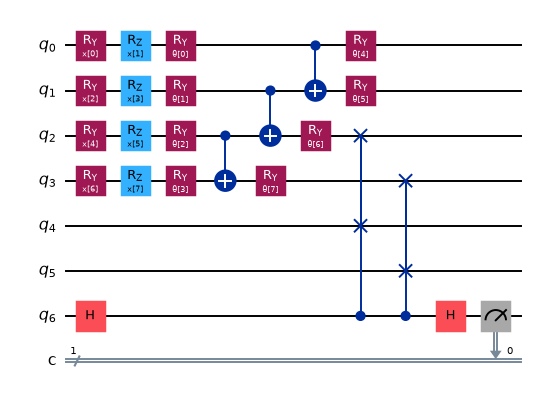

In [7]:
def n_qubits(enc, d):
    return {"dense": d // 2, "angle": d, "amplitude": int(math.ceil(math.log2(d)))}[enc]

def n_trash(enc, d):             # CHOICE: Dense 2 of 4, Angle 4 of 8, Amplitude 1 of 3 (the paper fixes only the dense case: q2, q3)
    return {"dense": n_qubits(enc, d) // 2, "angle": d // 2, "amplitude": 1}[enc]

def make_ansatz(kind, nq, reps, seed=0):
    if kind == "ra":
        return real_amplitudes(nq, reps=reps, entanglement="reverse_linear")   # CHOICE: entanglement (paper tried linear / reverse-linear / full)
    return pauli_two_design(nq, reps=reps, seed=seed)                          # PauliTwoDesign: random Pauli layer fixed by `seed`

# ---- the 7-qubit Qiskit circuit of Fig. 2a (Dense-Angle encoding + RealAmplitudes) ----
NQ, NT = n_qubits("dense", N_FEATURES), n_trash("dense", N_FEATURES)          # 4 data qubits, 2 trash qubits
XPAR = ParameterVector("x", N_FEATURES)
ANSATZ_QC = make_ansatz("ra", NQ, REPS)
QC = QuantumCircuit(NQ + NT + 1, 1)
for k in range(NQ):
    QC.ry(XPAR[2 * k], k); QC.rz(XPAR[2 * k + 1], k)                           # Dense-Angle encoding: two features per qubit
QC.compose(ANSATZ_QC, qubits=list(range(NQ)), inplace=True)                     # encoder
AUX = NQ + NT
QC.h(AUX)
for t in range(NT):
    QC.cswap(AUX, NQ - NT + t, NQ + t)                                          # trash qubit t <-> reference qubit t
QC.h(AUX); QC.measure(AUX, 0)
LOGICAL = list(ANSATZ_QC.parameters) + list(XPAR)                               # [8 trainable theta, 8 data angles]
COL = [LOGICAL.index(p) for p in QC.parameters]                                 # column order Qiskit expects
print("qubits:", QC.num_qubits, "| trainable parameters:", ANSATZ_QC.num_parameters, "| data angles:", len(XPAR))
QC.draw("mpl", fold=60, scale=0.7)

### 3.3 A fast, exact simulation of the same circuit

Training evaluates the circuit for batches of 64 events about 60 times, and testing scores 188,967 events - millions of
circuit runs in total. Because the reference qubits start in $|0\rangle$ the SWAP-test score only needs the data register:
the state is $U(\theta)\,|\psi(x)\rangle$ and $S$ is the probability that the trash qubits read 0. The functions below
compute exactly that with numpy (the trash qubits are the highest-index data qubits, i.e. the first $2^{n-k}$ amplitudes of
the output state). The next cell **verifies this shortcut against the Qiskit circuit above** (exact statevector of the
7-qubit circuit and a 1024-shot Aer run).

In [8]:
def encode(A, enc):
    """Product / amplitude states |psi(x)> for a batch of angle vectors A (n, d). Little-endian like Qiskit."""
    n, d = A.shape
    if enc == "dense":                              # qubit k: Ry(x_2k) then Rz(x_2k+1)  ->  [cos(a/2) e^{-ib/2}, sin(a/2) e^{ib/2}]
        psi = np.ones((n, 1), dtype=complex)
        for k in range(d // 2):
            a, b = A[:, 2 * k], A[:, 2 * k + 1]
            s = np.stack([np.cos(a / 2) * np.exp(-0.5j * b), np.sin(a / 2) * np.exp(0.5j * b)], axis=1)
            psi = (s[:, :, None] * psi[:, None, :]).reshape(n, -1)
        return psi
    if enc == "angle":                              # qubit k: Ry(x_k)
        psi = np.ones((n, 1))
        for k in range(d):
            s = np.stack([np.cos(A[:, k] / 2), np.sin(A[:, k] / 2)], axis=1)
            psi = (s[:, :, None] * psi[:, None, :]).reshape(n, -1)
        return psi.astype(complex)
    if enc == "amplitude":                          # the d features are the amplitudes of a ceil(log2 d)-qubit state
        dim = 2 ** int(math.ceil(math.log2(d)))
        v = np.zeros((n, dim)); v[:, :d] = A
        nrm = np.linalg.norm(v, axis=1, keepdims=True)
        zero = nrm[:, 0] < 1e-12
        v[zero, 0] = 1.0; nrm[zero] = 1.0           # CHOICE: an all-zero feature vector cannot be normalised -> |0...0>
        return (v / nrm).astype(complex)
    raise ValueError(enc)

def ansatz_unitary(ans, theta):
    return Operator(ans.assign_parameters(theta)).data

def qae_scores(A, enc, U, ntrash, chunk=16384):
    """Anomaly score A = 1 - S, S = probability that all trash qubits read 0 after the encoder (= exact SWAP-test fidelity)."""
    out = []
    for i in range(0, len(A), chunk):
        psi = encode(A[i:i + chunk], enc) @ U.T
        keep = psi.shape[1] // 2 ** ntrash
        out.append(1.0 - (np.abs(psi[:, :keep]) ** 2).sum(axis=1))
    return np.concatenate(out)

def qiskit_scores(A, theta, sampler, shots=SHOTS, chunk=500):
    """Anomaly scores 2L/M from the 7-qubit Qiskit circuit run on an Aer sampler (shot noise included)."""
    out = []
    for i in range(0, len(A), chunk):
        a = A[i:i + chunk]
        vals = np.hstack([np.tile(theta, (len(a), 1)), a])[:, COL]
        bits = sampler.run([(QC, vals)], shots=shots).result()[0].data.c
        L = np.array([bits.get_counts(k).get("1", 0) for k in range(len(a))])
        out.append(2.0 * L / shots)
    return np.concatenate(out)

# ---- check 1: numpy shortcut vs the exact statevector of the full 7-qubit circuit ----
rngc = np.random.default_rng(SEED)
theta_chk = rngc.uniform(-np.pi, np.pi, ANSATZ_QC.num_parameters)
A_chk = angle_scaler(sub0, FIRST_N)(Xte_all.iloc[:24])
QC_NM = QC.remove_final_measurements(inplace=False)
exact_qiskit = []
for a in A_chk:
    bound = QC_NM.assign_parameters(dict(zip(QC_NM.parameters, np.hstack([theta_chk, a])[COL])))
    exact_qiskit.append(2.0 * Statevector(bound).probabilities([AUX])[1])          # P(aux = 1) = L/M in the limit -> A = 2 P(1)
fast = qae_scores(A_chk, "dense", ansatz_unitary(ANSATZ_QC, theta_chk), NT)
print("max |numpy - Qiskit statevector| over 24 events:", np.abs(fast - np.array(exact_qiskit)).max())
assert np.allclose(fast, exact_qiskit, atol=1e-9)
# ---- check 2: 1024-shot Aer sampler (the paper's M-shot estimator 2L/M) ----
SAMPLER = AerSampler(default_shots=SHOTS, seed=SEED)
shot = qiskit_scores(A_chk, theta_chk, SAMPLER)
print("1024-shot scores 2L/M vs exact (first 6):", np.round(shot[:6], 3), np.round(fast[:6], 3), "| mean abs shot error", np.abs(shot - fast).mean().round(4))

max |numpy - Qiskit statevector| over 24 events: 3.3306690738754696e-16
1024-shot scores 2L/M vs exact (first 6): [0.951 0.912 0.951 0.971 0.967 0.92 ] [0.969 0.969 0.961 0.969 0.961 0.961] | mean abs shot error 0.0181


### 3.4 Training and evaluation helpers

`train_qae` follows Section 4.1: COBYLA, 60 iterations, batch size 64, cost = mean anomaly score $2L/M$ of the batch (here the
exact value of the same quantity). Every cost evaluation takes the next minibatch of a shuffled training subset. Anomalies are
events whose score exceeds the training mean plus two training standard deviations. `evaluate` reports accuracy, precision,
recall and F1 with *anomalous = positive*, macro-F1 (the F1 of the two classes averaged, because the paper does not say which
F1 it means), AUROC, false negatives / positives, and the paper's Eq. 6 **separation** computed from the mode of the score
histogram of each class.

In [9]:
def train_qae(A_train, enc=ENCODING, ans_kind=ANSATZ, reps=REPS, maxiter=MAXITER, batch=BATCH, seed=SEED, ntrash=None, verbose=False):
    rng = np.random.default_rng(seed)
    d = A_train.shape[1]; nq = n_qubits(enc, d); ntrash = n_trash(enc, d) if ntrash is None else ntrash
    ans = make_ansatz(ans_kind, nq, reps, seed=seed)
    P = encode(A_train, enc)
    order = rng.permutation(len(P)); ptr = [0]; history = []
    def cost(theta):
        if ptr[0] + batch > len(order): ptr[0] = 0
        b = order[ptr[0]:ptr[0] + batch]; ptr[0] += batch
        psi = P[b] @ ansatz_unitary(ans, theta).T
        c = float(1.0 - (np.abs(psi[:, :psi.shape[1] // 2 ** ntrash]) ** 2).sum(axis=1).mean())
        history.append(c); return c
    theta0 = rng.uniform(-np.pi, np.pi, ans.num_parameters)                    # CHOICE: initial parameters
    res = minimize(cost, theta0, method="COBYLA", options=dict(maxiter=maxiter, rhobeg=0.5))
    U = ansatz_unitary(ans, res.x)
    return dict(theta=res.x, U=U, ans=ans, enc=enc, ntrash=ntrash, history=np.array(history), nfev=res.nfev)

def mode_of(s, lo, hi, bins=50):
    h, e = np.histogram(s, bins=bins, range=(lo, hi)); k = int(np.argmax(h))
    return 0.5 * (e[k] + e[k + 1])

def evaluate(s_train, s_test, y_test, n_sigma=N_SIGMA):
    thr = s_train.mean() + n_sigma * s_train.std()
    pred = (s_test > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    lo, hi = float(min(s_train.min(), s_test.min())), float(max(s_train.max(), s_test.max()))
    ma, mn = mode_of(s_test[y_test == 1], lo, hi), mode_of(s_test[y_test == 0], lo, hi)
    return dict(threshold=thr, accuracy=accuracy_score(y_test, pred), precision=precision_score(y_test, pred, zero_division=0),
                recall=recall_score(y_test, pred), f1=f1_score(y_test, pred, zero_division=0),
                f1_macro=f1_score(y_test, pred, average="macro", zero_division=0), auroc=roc_auc_score(y_test, s_test),
                fp=int(fp), fn=int(fn), tp=int(tp), tn=int(tn), separation=(ma - mn) / ma if ma > 0 else float("nan"))

def make_split(sub_idx, cols, mode="unit", X_train=None, X_test=None):
    X_train = Xtr_all if X_train is None else X_train
    X_test = Xte_all if X_test is None else X_test
    sub = X_train.iloc[sub_idx]
    f = angle_scaler(sub, cols, mode)
    return f(sub), f(X_test)

# stratified test subsample used by the sweeps (same class ratio as the full test set)
_, SWEEP_IDX = train_test_split(np.arange(len(yte_all)), test_size=min(SWEEP_TEST_N, len(yte_all) - 1), stratify=yte_all, random_state=SEED)
print("sweep test subsample:", len(SWEEP_IDX), f"events, {100 * yte_all[SWEEP_IDX].mean():.1f} % anomalous")

sweep test subsample: 30000 events, 90.7 % anomalous


## 4. The paper's headline model: Dense-Angle + RealAmplitudes, first 8 features, first 5,000 normal events

This is the paper's "first run" row of Table 5 (F1 0.87, AUROC 0.965). We train on the first 5,000 normal training events in file
order, with the seed fixed, and test on the **full** 188,967-event test set.

trained in 1.3 s (60 COBYLA cost evaluations); training cost 0.958 -> 0.152
learned parameters: [-1.415 -2.803 -1.321  4.613  0.407 -1.278 -2.5    1.535]


,threshold,accuracy,precision,recall,f1,f1_macro,auroc,fp,fn,tp,tn,separation
QAE first run (seed 42),0.3993,0.8914,0.9947,0.885,0.9366,0.778,0.9138,815.0,19712.0,151747.0,16693.0,0.83


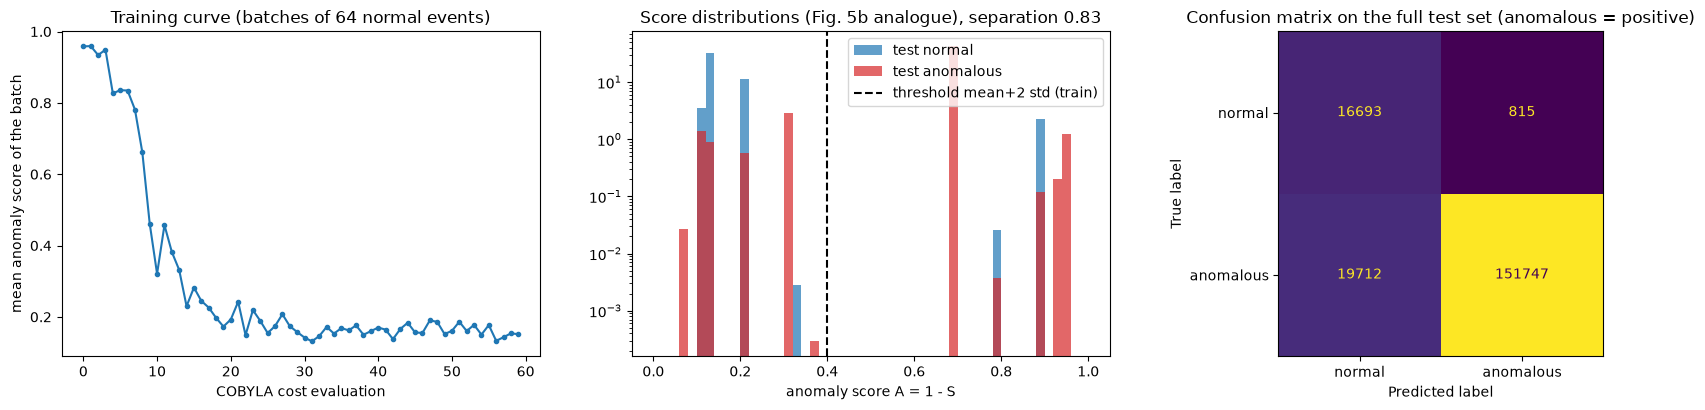

In [10]:
t0 = time.time()
A_tr, A_te = make_split(NORMAL_IDX[:N_TRAIN], FIRST_N)
model = train_qae(A_tr, seed=SEED)
s_tr = qae_scores(A_tr, "dense", model["U"], model["ntrash"]); s_te = qae_scores(A_te, "dense", model["U"], model["ntrash"])
res_first = evaluate(s_tr, s_te, yte_all)
print(f"trained in {time.time() - t0:.1f} s ({model['nfev']} COBYLA cost evaluations); training cost {model['history'][0]:.3f} -> {model['history'][-1]:.3f}")
print("learned parameters:", np.round(model["theta"], 3))
display(pd.Series(res_first).to_frame("QAE first run (seed 42)").T.round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(model["history"], marker="o", ms=3); ax[0].set_xlabel("COBYLA cost evaluation"); ax[0].set_ylabel("mean anomaly score of the batch")
ax[0].set_title("Training curve (batches of 64 normal events)")
bins = np.linspace(0, 1, 51)
ax[1].hist(s_te[yte_all == 0], bins=bins, alpha=0.7, label="test normal", color="tab:blue", density=True)
ax[1].hist(s_te[yte_all == 1], bins=bins, alpha=0.7, label="test anomalous", color="tab:red", density=True)
ax[1].axvline(res_first["threshold"], color="k", ls="--", label="threshold mean+2 std (train)")
ax[1].set_yscale("log"); ax[1].set_xlabel("anomaly score A = 1 - S"); ax[1].set_title(f"Score distributions (Fig. 5b analogue), separation {res_first['separation']:.2f}"); ax[1].legend()
cm = np.array([[res_first["tn"], res_first["fp"]], [res_first["fn"], res_first["tp"]]])
ConfusionMatrixDisplay(cm, display_labels=["normal", "anomalous"]).plot(ax=ax[2], values_format="d", colorbar=False)
ax[2].set_title("Confusion matrix on the full test set (anomalous = positive)")
plt.tight_layout(); plt.show()

**How to read the numbers.** The test set is **90.7 % anomalous**, so a detector that flags *everything* already has recall 1,
precision 0.907 and an anomalous-class F1 of 0.951. The paper's best F1 (0.87) is below that, so the paper's F1 is probably an
average over both classes (macro or weighted) rather than the anomalous-class F1. Because the paper does not say, both are
printed everywhere: `f1` is the F1 of the anomalous class, `f1_macro` the mean of the two classes' F1. AUROC, which does not
depend on a threshold or on the class ratio, is the cleanest number to compare.

## 5. The classical benchmark and other baselines on the same inputs

The paper's benchmark is a **classical autoencoder** (Adam, mean absolute error, anomaly score = reconstruction MAE, same
$\mu + 2\sigma$ threshold). Its architecture is in a supplement that the PDF text does not contain, so this notebook uses a
symmetric dense network `d - 16 - 8 - 4 - 8 - 16 - d` (CHOICE) and a fixed number of gradient steps (CHOICE: `CAE_STEPS`; the
number of epochs follows from the sample size). It receives exactly the QAE's inputs (the angles divided by $\pi$), either the
first 8 features or all 24.

For context we add four more baselines on the same 8 inputs: an isolation forest and a one-class SVM (unsupervised, normal
events only, same threshold rule), and a random forest and an RBF-SVC (supervised: they also see the 1,269 labelled
anomalies of the training split, which the autoencoders never see), plus the trivial "flag everything" detector.

In [11]:
def train_cae(A_unit, seed, steps, batch=BATCH):
    d = A_unit.shape[1]; keras.utils.set_random_seed(seed)
    m = keras.Sequential([keras.layers.Input((d,)), keras.layers.Dense(16, activation="relu"), keras.layers.Dense(8, activation="relu"),
                          keras.layers.Dense(4, activation="relu"),                           # latent layer
                          keras.layers.Dense(8, activation="relu"), keras.layers.Dense(16, activation="relu"), keras.layers.Dense(d)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")                              # paper: Adam + MAE
    epochs = max(1, int(math.ceil(steps / math.ceil(len(A_unit) / batch))))
    m.fit(A_unit, A_unit, epochs=epochs, batch_size=batch, shuffle=True, verbose=0)
    return m

def cae_scores(m, A_unit):
    return np.abs(m.predict(A_unit, batch_size=8192, verbose=0) - A_unit).mean(axis=1)

COLS8, COLS24 = PAPER_ORDER[:8], PAPER_ORDER
RESULTS = []                      # one row per (experiment, model, repeat)
def log(experiment, model_name, feats, n_train, repeat, m, t=np.nan):
    RESULTS.append(dict(experiment=experiment, model=model_name, features=feats, n_train=n_train, repeat=repeat, seconds=t, **m))

def run_qae(sub_idx, seed, cols=COLS8, mode="unit", **kw):
    A_tr, A_te = make_split(sub_idx, cols, mode)
    mdl = train_qae(A_tr, seed=seed, **kw)
    enc = kw.get("enc", ENCODING)
    return evaluate(qae_scores(A_tr, enc, mdl["U"], mdl["ntrash"]), qae_scores(A_te, enc, mdl["U"], mdl["ntrash"]), yte_all), mdl

SCORES = {}                       # test-set score vectors kept for the distribution plots
def run_cae(sub_idx, seed, cols, steps=None, batch=BATCH, keep=None):
    sub = Xtr_all.iloc[sub_idx]; f = angle_scaler(sub, cols)
    A_tr, A_te = f(sub) / np.pi, f(Xte_all) / np.pi
    m = train_cae(A_tr, seed, CAE_STEPS if steps is None else steps, batch)
    s_tr, s_te = cae_scores(m, A_tr), cae_scores(m, A_te)
    if keep: SCORES[keep] = s_te
    return evaluate(s_tr, s_te, yte_all)

def trivial_detector():
    pred = np.ones_like(yte_all)
    return dict(threshold=np.nan, accuracy=accuracy_score(yte_all, pred), precision=precision_score(yte_all, pred), recall=1.0,
                f1=f1_score(yte_all, pred), f1_macro=f1_score(yte_all, pred, average="macro"), auroc=0.5,
                fp=int(((pred == 1) & (yte_all == 0)).sum()), fn=0, tp=int(yte_all.sum()), tn=0, separation=np.nan)
log("baseline", "flag everything", 8, 0, 0, trivial_detector())
print("trivial 'flag everything' detector:", {k: round(v, 3) for k, v in trivial_detector().items() if k in ("accuracy", "precision", "recall", "f1", "f1_macro", "auroc")})

trivial 'flag everything' detector: {'accuracy': 0.907, 'precision': 0.907, 'recall': 1.0, 'f1': 0.951, 'f1_macro': 0.476, 'auroc': 0.5}


## 6. Table 5: repeated random 5,000-event subsets

The paper averages over repeated random subsets of 5,000 normal training events ("all averages show mean +- sigma across
repeated 5k random subsets"). We do the same with `N_REPEATS` different random subsets (a fresh QAE with fresh random initial
parameters and a fresh CAE per subset), always testing on the full test set. The classical baselines use the first
`BASE_REPEATS` subsets only (the SVMs are slow at this test-set size).

In [12]:
def baseline_models(sub_idx, seed):
    """Isolation forest + one-class SVM (normal events only), random forest + RBF-SVC (see the labelled training anomalies)."""
    sub = Xtr_all.iloc[sub_idx]; f = angle_scaler(sub, COLS8)
    A_tr, A_te = f(sub), f(Xte_all)
    out = {}
    iso = IsolationForest(n_estimators=100, random_state=seed).fit(A_tr)
    out["isolation forest"] = evaluate(-iso.score_samples(A_tr), -iso.score_samples(A_te), yte_all)
    oc = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(A_tr)                         # CHOICE: nu = 0.05
    out["one-class SVM"] = evaluate(-oc.decision_function(A_tr), -oc.decision_function(A_te), yte_all)
    # supervised baselines: the same 5,000 normal events + all labelled training anomalies (sus = 1), same angle scaling
    sus_idx = np.where(ytr_all == 1)[0]
    A_sus = f(Xtr_all.iloc[sus_idx]); Xs = np.vstack([A_tr, A_sus]); ys = np.r_[np.zeros(len(A_tr)), np.ones(len(A_sus))].astype(int)
    for name, clf in [("random forest (supervised)", RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2)),
                      ("RBF-SVC (supervised)", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed))]:
        clf.fit(Xs, ys)
        score = clf.predict_proba(A_te)[:, 1] if hasattr(clf, "predict_proba") else clf.decision_function(A_te)
        pred = clf.predict(A_te)
        m = evaluate(np.zeros(2), score, yte_all); thr = np.nan
        tn, fp, fn, tp = confusion_matrix(yte_all, pred, labels=[0, 1]).ravel()
        m.update(accuracy=accuracy_score(yte_all, pred), precision=precision_score(yte_all, pred, zero_division=0), recall=recall_score(yte_all, pred),
                 f1=f1_score(yte_all, pred), f1_macro=f1_score(yte_all, pred, average="macro"), fp=int(fp), fn=int(fn), tp=int(tp), tn=int(tn), threshold=thr)
        out[name] = m
    return out

t_start = time.time()
for r in range(N_REPEATS):
    sub_idx = np.sort(np.random.default_rng(SEED + r).choice(NORMAL_IDX, N_TRAIN, replace=False))
    t0 = time.time(); m, _ = run_qae(sub_idx, SEED + r); log("table5", "QAE dense/RA/1", 8, N_TRAIN, r, m, time.time() - t0)
    t0 = time.time(); m = run_cae(sub_idx, SEED + r, COLS8); log("table5", "CAE", 8, N_TRAIN, r, m, time.time() - t0)
    t0 = time.time(); m = run_cae(sub_idx, SEED + r, COLS24); log("table5", "CAE", 24, N_TRAIN, r, m, time.time() - t0)
    if r < BASE_REPEATS:
        for name, m in baseline_models(sub_idx, SEED + r).items(): log("table5", name, 8, N_TRAIN, r, m)
    print(f"repeat {r + 1}/{N_REPEATS} done ({time.time() - t_start:.0f} s)", end="\r")
print()
T5 = pd.DataFrame([r for r in RESULTS if r["experiment"] == "table5"])
METRIC_COLS = ["f1", "f1_macro", "auroc", "precision", "recall", "fp", "fn"]
agg = T5.groupby(["model", "features"])[METRIC_COLS].agg(["mean", "std"])
agg.columns = [f"{a} {b}" for a, b in agg.columns]
display(agg.round(3))

repeat 10/10 done (586 s)


f1 mean  f1 std  f1_macro mean  f1_macro std  auroc mean  auroc std  precision mean  precision std  recall mean  recall std   fp mean   fp std     fn mean     fn std
model                      features                                                                                                                                                                       
CAE                        8           0.950   0.019          0.818         0.053       0.950      0.041           0.996          0.005        0.909       0.034   563.100  768.481   15594.900   5796.006
                           24          0.759   0.365          0.638         0.280       0.917      0.062           0.936          0.126        0.709       0.355  1051.400  980.295   49978.000  60848.523
QAE dense/RA/1             8           0.547   0.428          0.490         0.353       0.878      0.088           0.964          0.040        0.496       0.442   812.300    4.347   86488.300  75781.140
RBF-SVC (supervised)       8           0.049   0.000          0.111         0.000       0.969      0.000           0.987          0.000        0.025       0.000    55.000    0.000  167140.000      0.000
isolation forest           8           0.948   0.001          0.768         0.003       0.841      0.036           0.969          0.001        0.928       0.001  5109.333   84.056   12321.333    221.618
one-class SVM              8           0.969   0.000          0.867         0.002       0.967      0.001           0.998          0.001        0.941       0.000   331.667  154.730   10155.000      0.000
random forest (supervised) 8           0.043   0.010          0.108         0.005       0.973      0.002           0.985          0.004        0.022       0.005    55.000    0.000  167666.667    904.419

### Models trained on the full normal training set

The paper also trains the CAE on all 761,875 normal training events (QAE training on the full set was too slow for them, and
is here too). One run each, batch size 256 and `CAE_FULL_STEPS` gradient steps (CHOICE).

In [13]:
for cols, nf in [(COLS8, 8), (COLS24, 24)]:
    t0 = time.time()
    m = run_cae(NORMAL_IDX, SEED, cols, steps=CAE_FULL_STEPS, batch=256, keep=f"cae{nf}_full")
    log("full", "CAE", nf, len(NORMAL_IDX), 0, m, time.time() - t0)
FULL = pd.DataFrame([r for r in RESULTS if r["experiment"] == "full"])
display(FULL[["model", "features", "n_train", "f1", "f1_macro", "auroc", "precision", "recall", "fp", "fn", "separation", "seconds"]].round(3))

,model,features,n_train,f1,f1_macro,auroc,precision,recall,fp,fn,separation,seconds
0,CAE,8,761875,0.939,0.788,0.969,0.999,0.885,137,19653,0.978,61.701
1,CAE,24,761875,0.944,0.794,0.958,0.994,0.899,907,17388,0.976,64.699


## 7. Fig. 4: the effect of the training-set size

QAE and CAE (8 features) trained on 1,000 / 5,000 / 10,000 / 20,000 normal events (`SIZES`), `SIZE_REPEATS` random subsets
each, with the full-data CAE as a horizontal reference. The paper plots AUROC, false negatives and false positives.

size 20000 done (443 s)


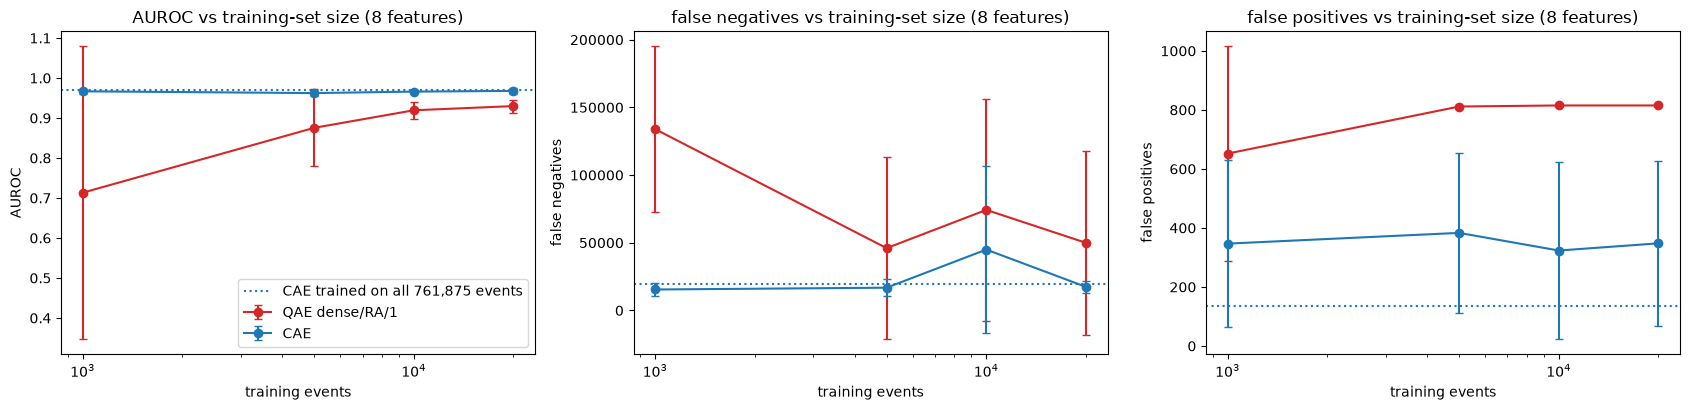

auroc            f1        f1_macro               fn                fp         
                         mean    std   mean    std     mean    std      mean        std   mean      std
model          n_train                                                                                 
CAE            1000     0.967  0.005  0.952  0.016    0.821  0.042   15448.6   4906.857  346.8  282.936
               5000     0.962  0.007  0.947  0.019    0.811  0.050   16778.4   6120.498  383.2  270.456
               10000    0.966  0.004  0.791  0.347    0.679  0.283   44945.8  61906.865  323.4  301.069
               20000    0.968  0.008  0.945  0.014    0.804  0.036   17373.6   4409.836  347.8  279.640
QAE dense/RA/1 1000     0.713  0.367  0.272  0.369    0.262  0.272  133920.2  61429.429  652.0  364.479
               5000     0.875  0.096  0.771  0.397    0.672  0.317   46010.4  67418.335  811.4    4.930
               10000    0.919  0.021  0.605  0.479    0.545  0.386   74264.4  81880.612  815.0    0.000
               20000    0.930  0.016  0.750  0.417    0.643  0.316   49925.8  67918.795  815.0    0.000

In [14]:
t_start = time.time()
for n in SIZES:
    for r in range(SIZE_REPEATS):
        if n == N_TRAIN and r < N_REPEATS:
            continue                                                # already computed in Section 6 (same subsets)
        sub_idx = np.sort(np.random.default_rng(SEED + 1000 * n + r).choice(NORMAL_IDX, n, replace=False))
        m, _ = run_qae(sub_idx, SEED + r); log("sizes", "QAE dense/RA/1", 8, n, r, m)
        m = run_cae(sub_idx, SEED + r, COLS8); log("sizes", "CAE", 8, n, r, m)
    print(f"size {n} done ({time.time() - t_start:.0f} s)", end="\r")
print()
R = pd.DataFrame(RESULTS)
S = R[(R.features == 8) & (R.model.isin(["QAE dense/RA/1", "CAE"])) & (R.experiment.isin(["sizes", "table5"])) & (R.n_train.isin(SIZES))
      & (R["repeat"] < SIZE_REPEATS)]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cae_full = R[(R.experiment == "full") & (R.features == 8)].iloc[0]
for a, (col, ttl) in zip(ax, [("auroc", "AUROC"), ("fn", "false negatives"), ("fp", "false positives")]):
    for mdl, c in [("QAE dense/RA/1", "tab:red"), ("CAE", "tab:blue")]:
        g = S[S.model == mdl].groupby("n_train")[col].agg(["mean", "std"]).reindex(SIZES)
        a.errorbar(g.index, g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3, color=c, label=mdl)
    a.axhline(cae_full[col], color="tab:blue", ls=":", label="CAE trained on all 761,875 events")
    a.set_xscale("log"); a.set_xlabel("training events"); a.set_ylabel(ttl); a.set_title(f"{ttl} vs training-set size (8 features)")
ax[0].legend(); plt.tight_layout(); plt.show()
size_tab = S.groupby(["model", "n_train"])[["auroc", "f1", "f1_macro", "fn", "fp"]].agg(["mean", "std"]).round(3)
display(size_tab)

## 8. Fig. 5: score distributions and the "separation"

Eq. 6 defines $\text{separation} = (\text{mode}_{anomaly} - \text{mode}_{normal}) / \text{mode}_{anomaly}$. The paper reports 0.84
for the 24-feature CAE trained on all data and 0.97 for the best QAE. Here the mode of each class's score histogram
(50 bins over the common score range) is used; the paper does not say how its modes were found.

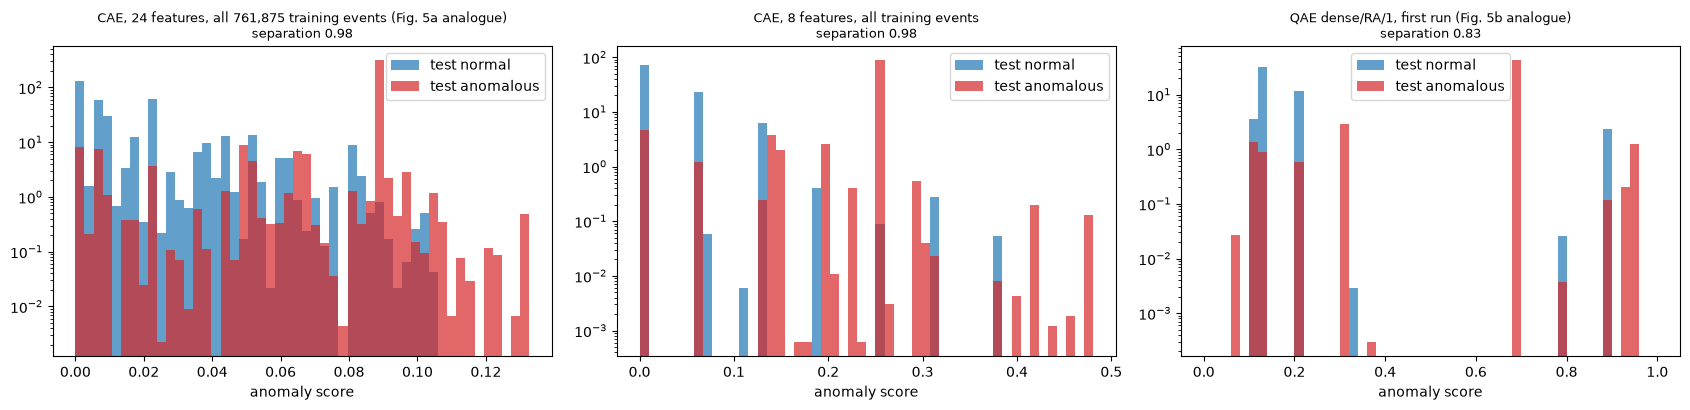

separation: CAE-24F-full 0.98 (paper 0.84) | CAE-8F-full 0.98 | QAE first run 0.83 (paper 0.97)


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
panels = [("CAE, 24 features, all 761,875 training events (Fig. 5a analogue)", SCORES["cae24_full"], None),
          ("CAE, 8 features, all training events", SCORES["cae8_full"], None),
          ("QAE dense/RA/1, first run (Fig. 5b analogue)", s_te, None)]
sep_rows = {}
for a, (ttl, sc, _) in zip(ax, panels):
    hi = float(np.quantile(sc, 0.999)) if "CAE" in ttl else 1.0
    bins = np.linspace(0, hi, 51)
    a.hist(np.clip(sc[yte_all == 0], 0, hi), bins=bins, alpha=0.7, density=True, label="test normal", color="tab:blue")
    a.hist(np.clip(sc[yte_all == 1], 0, hi), bins=bins, alpha=0.7, density=True, label="test anomalous", color="tab:red")
    lo_, hi_ = float(sc.min()), float(sc.max())
    ma, mn = mode_of(sc[yte_all == 1], lo_, hi_), mode_of(sc[yte_all == 0], lo_, hi_)
    sep_rows[ttl] = (ma - mn) / ma
    a.set_yscale("log"); a.set_title(f"{ttl}\nseparation {sep_rows[ttl]:.2f}", fontsize=9); a.set_xlabel("anomaly score"); a.legend()
plt.tight_layout(); plt.show()
SEP_CAE24, SEP_CAE8, SEP_QAE = list(sep_rows.values())
print(f"separation: CAE-24F-full {SEP_CAE24:.2f} (paper 0.84) | CAE-8F-full {SEP_CAE8:.2f} | QAE first run {SEP_QAE:.2f} (paper 0.97)")

## 9. Table 4: encodings, ansatz types and repetitions (First-N features)

The paper compares three encodings that fit 8 features (**Amplitude**: 3 qubits, **Angle**: 8 qubits, **Dense-Angle**: 4
qubits) plus EfficientSU2 encoding with 24 features, each with a RealAmplitudes (RA) or a PauliTwoDesign (Pauli) ansatz and
1 or 3 repetitions, trained on 1,000 events. EfficientSU2 encoding is not run here: the paper does not specify how 16 / 24
features map onto its circuit. Each cell below is the mean over `SWEEP_SEEDS` random 1,000-event subsets; test metrics use a
stratified `SWEEP_TEST_N`-event subsample of the test set (same class ratio) to keep the 8-qubit Angle runs affordable.
The paper's numbers are single runs.

In [16]:
PAPER_T4 = {("amplitude", "ra", 1): (0.72, 0.872), ("amplitude", "ra", 3): (0.75, 0.899), ("amplitude", "pauli", 1): (0.72, 0.790), ("amplitude", "pauli", 3): (0.64, 0.424),
            ("angle", "ra", 1): (0.74, 0.864), ("angle", "ra", 3): (0.85, 0.896), ("angle", "pauli", 1): (0.73, 0.900), ("angle", "pauli", 3): (0.73, 0.835),
            ("dense", "ra", 1): (0.86, 0.960), ("dense", "ra", 3): (0.86, 0.955), ("dense", "pauli", 1): (0.72, 0.918), ("dense", "pauli", 3): (0.72, 0.096)}
y_sw = yte_all[SWEEP_IDX]; Xte_sw = Xte_all.iloc[SWEEP_IDX]

def sweep_qae(sub_idx, cols, seed, enc, ans_kind, reps, mode="unit"):
    sub = Xtr_all.iloc[sub_idx]; f = angle_scaler(sub, cols, mode)
    A_tr, A_te = f(sub), f(Xte_sw)
    mdl = train_qae(A_tr, enc=enc, ans_kind=ans_kind, reps=reps, seed=seed)
    return evaluate(qae_scores(A_tr, enc, mdl["U"], mdl["ntrash"]), qae_scores(A_te, enc, mdl["U"], mdl["ntrash"]), y_sw)

t_start = time.time(); rows = []
for (enc, ans_kind, reps), (pf1, pauc) in PAPER_T4.items():
    ms = []
    for s in range(SWEEP_SEEDS):
        sub_idx = np.sort(np.random.default_rng(SEED + 7 * s).choice(NORMAL_IDX, SWEEP_TRAIN_N, replace=False))
        m = sweep_qae(sub_idx, COLS8, SEED + s, enc, ans_kind, reps); ms.append(m)
        log("table4", f"{enc}/{ans_kind}/{reps}", 8, SWEEP_TRAIN_N, s, m)
    d = pd.DataFrame(ms)
    rows.append(dict(encoding=enc, ansatz=ans_kind, reps=reps, f1=d.f1.mean(), f1_std=d.f1.std(), f1_macro=d.f1_macro.mean(), auroc=d.auroc.mean(), auroc_std=d.auroc.std(),
                     paper_f1=pf1, paper_auroc=pauc))
    print(f"{enc}/{ans_kind}/{reps} done ({time.time() - t_start:.0f} s)", end="\r")
print()
T4 = pd.DataFrame(rows)
display(T4.round(3))
best_ours = T4.sort_values("auroc", ascending=False).iloc[0]
print("best configuration here (by mean AUROC):", best_ours.encoding, best_ours.ansatz, int(best_ours.reps), "| paper's best: dense ra 1")

dense/pauli/3 done (133 s)


,encoding,ansatz,reps,f1,f1_std,f1_macro,auroc,auroc_std,paper_f1,paper_auroc
0,amplitude,ra,1,0.006,0.011,0.077,0.775,0.019,0.72,0.872
1,amplitude,ra,3,0.023,0.022,0.080,0.689,0.118,0.75,0.899
2,amplitude,pauli,1,0.013,0.011,0.079,0.765,0.012,0.72,0.790
3,amplitude,pauli,3,0.006,0.011,0.077,0.773,0.009,0.64,0.424
4,angle,ra,1,0.613,0.531,0.522,0.907,0.034,0.74,0.864
5,angle,ra,3,0.306,0.530,0.303,0.906,0.002,0.85,0.896
6,angle,pauli,1,0.919,0.000,0.741,0.910,0.015,0.73,0.900
7,angle,pauli,3,0.919,0.000,0.741,0.895,0.012,0.73,0.835
8,dense,ra,1,0.667,0.479,0.581,0.851,0.103,0.86,0.960
9,dense,ra,3,0.963,0.002,0.835,0.924,0.040,0.86,0.955


best configuration here (by mean AUROC): dense ra 3 | paper's best: dense ra 1


## 10. Table 2: feature-selection strategies

The paper reduces the 24 features to 8 in several ways and reports the F1 (mean +- sigma over Amplitude and Dense-Angle
encodings) of each. The strategies are implemented here as follows (the paper only names them):

* **First-N**: the first 8 features of the list;
* **ANOVA**, **Mutual information**, **Kendall**: the 8 features with the highest ANOVA F-value / mutual information /
  absolute Kendall tau with the `sus` label *on the training split* (a supervised choice, computed once on all training
  anomalies plus a random 30,000 normal events for MI and Kendall);
* **Least correlated**: greedy choice of 8 features with the smallest mean absolute correlation with the other features;
* **PCA (filtering)**: the 8 original features with the largest variance-weighted squared loadings on the 8 leading
  principal components; **PCA (reduction)**: the 8 principal components themselves (min-max scaled to $[0, \pi]$);
* **Autoencoder-based reduction**: the 8-dimensional latent code of a classical autoencoder (24-16-8-16-24) trained on the same
  1,000 events, min-max scaled.

Each strategy is run with both encodings, RealAmplitudes, 1 repetition, `SWEEP_SEEDS` seeds, 1,000 training events.

In [17]:
# --- label-based column rankings (computed once, on the training split) ---
lab_idx = np.r_[np.where(ytr_all == 1)[0], np.random.default_rng(SEED).choice(NORMAL_IDX, 30000, replace=False)]
Xlab, ylab = Xtr_all.iloc[lab_idx].to_numpy(float), ytr_all[lab_idx]
F_anova = np.nan_to_num(f_classif(Xtr_all.to_numpy(float), ytr_all)[0])
MI = mutual_info_classif(Xlab, ylab, random_state=SEED)
KT = np.array([abs(np.nan_to_num(kendalltau(Xlab[:, j], ylab)[0])) for j in range(24)])
top8 = lambda v: [PAPER_ORDER[j] for j in np.argsort(-v)[:8]]
COLSEL = {"First-N": COLS8, "ANOVA": top8(F_anova), "Mutual Information": top8(MI), "Kendall's": top8(KT)}

def least_correlated(sub_df, k=8):
    with np.errstate(invalid="ignore", divide="ignore"):          # constant columns give NaN correlations -> treated as 0
        C = np.abs(np.nan_to_num(np.corrcoef(sub_df.to_numpy(float).T)))
    np.fill_diagonal(C, 0)
    return [PAPER_ORDER[j] for j in np.argsort(C.mean(axis=1))[:k]]

def selection_angles(strategy, sub_idx, seed):
    """(A_train, A_test_sweep, columns or None) for a feature-selection strategy; fitted on the training subset only."""
    sub = Xtr_all.iloc[sub_idx]
    if strategy in COLSEL:
        cols = COLSEL[strategy]
    elif strategy == "Least Correlated":
        cols = least_correlated(sub)
    elif strategy == "PCA (filtering)":
        A24 = angle_scaler(sub, PAPER_ORDER)(sub) / np.pi
        p = PCA(n_components=8, random_state=seed).fit(A24)
        cols = [PAPER_ORDER[j] for j in np.argsort(-(p.explained_variance_ratio_[:, None] * p.components_ ** 2).sum(0))[:8]]
    else:
        f24 = angle_scaler(sub, PAPER_ORDER); A24, T24 = f24(sub) / np.pi, f24(Xte_sw) / np.pi
        if strategy == "PCA (reduction)":
            p = PCA(n_components=8, random_state=seed).fit(A24); Z, T = p.transform(A24), p.transform(T24)
        else:                                                    # "Autoencoder-based reduction": 8-d latent code
            keras.utils.set_random_seed(seed)
            inp = keras.layers.Input((24,)); h = keras.layers.Dense(16, activation="relu")(inp); z = keras.layers.Dense(8, activation="relu")(h)
            out = keras.layers.Dense(24)(keras.layers.Dense(16, activation="relu")(z))
            ae = keras.Model(inp, out); ae.compile("adam", "mae")
            ae.fit(A24, A24, epochs=max(1, int(math.ceil(CAE_STEPS / 3 / math.ceil(len(A24) / BATCH)))), batch_size=BATCH, verbose=0)
            enc_model = keras.Model(inp, z); Z, T = enc_model.predict(A24, verbose=0), enc_model.predict(T24, batch_size=8192, verbose=0)
        lo, hi = Z.min(0), Z.max(0); span = np.where(hi - lo > 1e-12, hi - lo, 1.0)       # min-max to [0, pi], test clipped
        return np.clip((Z - lo) / span, 0, 1) * np.pi, np.clip((T - lo) / span, 0, 1) * np.pi, None
    f = angle_scaler(sub, cols)
    return f(sub), f(Xte_sw), cols

PAPER_T2 = {"First-N": (0.798, 0.063), "Autoencoder-based reduction": (0.695, 0.069), "PCA (reduction)": (0.628, 0.143), "PCA (filtering)": (0.685, 0.045),
            "Mutual Information": (0.705, 0.065), "ANOVA": (0.440, 0.350), "Kendall's": (0.460, 0.262), "Least Correlated": (0.380, 0.300)}
t_start = time.time(); rows = []; sel_cols = {}
for strat, (pm, ps) in PAPER_T2.items():
    ms = []
    for enc in ("amplitude", "dense"):
        for s in range(SWEEP_SEEDS):
            sub_idx = np.sort(np.random.default_rng(SEED + 7 * s).choice(NORMAL_IDX, SWEEP_TRAIN_N, replace=False))
            A_tr_s, A_te_s, cols = selection_angles(strat, sub_idx, SEED + s)
            if cols is not None: sel_cols[strat] = cols
            mdl = train_qae(A_tr_s, enc=enc, seed=SEED + s)
            m = evaluate(qae_scores(A_tr_s, enc, mdl["U"], mdl["ntrash"]), qae_scores(A_te_s, enc, mdl["U"], mdl["ntrash"]), y_sw); ms.append(m)
            log("table2", strat, 8, SWEEP_TRAIN_N, s, dict(m, encoding=enc))
    d = pd.DataFrame(ms)
    rows.append(dict(strategy=strat, f1=d.f1.mean(), f1_std=d.f1.std(), f1_macro=d.f1_macro.mean(), f1_macro_std=d.f1_macro.std(), auroc=d.auroc.mean(), auroc_std=d.auroc.std(),
                     paper_f1=pm, paper_f1_std=ps))
    print(f"{strat} done ({time.time() - t_start:.0f} s)", end="\r")
print()
T2 = pd.DataFrame(rows)
display(T2.round(3))
print("columns chosen (First-N and the label-based strategies are the same for every seed; the others are shown for the last seed):")
for k, v in sel_cols.items(): print(f"  {k:20s} {v}")

Least Correlated done (114 s)


,strategy,f1,f1_std,f1_macro,f1_macro_std,auroc,auroc_std,paper_f1,paper_f1_std
0,First-N,0.337,0.472,0.329,0.368,0.813,0.078,0.798,0.063
1,Autoencoder-based reduction,0.056,0.046,0.100,0.026,0.650,0.306,0.695,0.069
2,PCA (reduction),0.184,0.358,0.194,0.252,0.402,0.316,0.628,0.143
3,PCA (filtering),0.009,0.008,0.082,0.004,0.501,0.248,0.685,0.045
4,Mutual Information,0.343,0.477,0.329,0.374,0.799,0.121,0.705,0.065
5,ANOVA,0.348,0.477,0.343,0.388,0.692,0.190,0.440,0.350
6,Kendall's,0.027,0.029,0.087,0.018,0.471,0.158,0.460,0.262
7,Least Correlated,0.322,0.499,0.342,0.402,0.567,0.376,0.380,0.300


columns chosen (First-N and the label-based strategies are the same for every seed; the others are shown for the last seed):
  First-N              ['processId', 'parentProcessId', 'userId', 'mountNamespace', 'returnValue', 'processName', 'threadId', 'eventId']
  PCA (filtering)      ['mountNamespace', 'parentProcessId', 'returnValue', 'argsNum', 'processId', 'processName', 'arg1_value', 'eventId']
  Mutual Information   ['threadId', 'processName', 'userId', 'arg2_value', 'arg1_value', 'arg4_value', 'parentProcessId', 'arg3_value']
  ANOVA                ['threadId', 'userId', 'arg2_value', 'arg1_value', 'processName', 'arg4_value', 'arg3_value', 'parentProcessId']
  Kendall's            ['userId', 'parentProcessId', 'processName', 'threadId', 'arg2_value', 'arg1_value', 'arg4_value', 'arg3_value']
  Least Correlated     ['userId', 'threadId', 'arg2_value', 'parentProcessId', 'mountNamespace', 'processName', 'processId', 'arg1_value']


## 11. How much do the paper's unspecified choices matter?

Three choices that the paper leaves open were fixed in advance (feature order, angle scaling, number of COBYLA iterations
beyond 60). The sensitivity runs below repeat the headline experiment (Dense / RA / 1 repetition, 5,000 events) with the
alternative of each, on `SENS_REPEATS` random subsets.

In [18]:
SENS_REPEATS = min(5, N_REPEATS)
variants = {"headline (Section 3 order, a-priori unit scaling)": dict(),
            "min-max scaling of every feature": dict(mode="minmax"),
            "CSV column order for First-8": dict(cols=CSV_ORDER[:8]),
            "COBYLA maxiter 300 instead of 60": dict(maxiter=300)}
rows = []
for name, kw in variants.items():
    ms = []; nfevs = []
    for r in range(SENS_REPEATS):
        sub_idx = np.sort(np.random.default_rng(SEED + r).choice(NORMAL_IDX, N_TRAIN, replace=False))
        if name.startswith("headline"):
            m = [x for x in RESULTS if x["experiment"] == "table5" and x["model"] == "QAE dense/RA/1" and x["repeat"] == r][0]
            nfevs.append(np.nan)                                   # (the headline runs used the full budget of MAXITER evaluations)
        else:
            cols = kw.get("cols", COLS8)
            m, mdl_ = run_qae(sub_idx, SEED + r, cols=cols, **{k: v for k, v in kw.items() if k != "cols"})
            nfevs.append(mdl_["nfev"])
        ms.append(m)
    d = pd.DataFrame(ms)
    rows.append({"variant": name, "AUROC": f"{d.auroc.mean():.3f} +- {d.auroc.std():.3f}", "F1 (anomalous)": f"{d.f1.mean():.3f} +- {d.f1.std():.3f}",
                 "F1 (macro)": f"{d.f1_macro.mean():.3f} +- {d.f1_macro.std():.3f}", "runs with F1 < 0.5": int((d.f1 < 0.5).sum()),
                 "COBYLA cost evaluations (mean)": MAXITER if name.startswith("headline") else float(np.mean(nfevs))})
    if not name.startswith("headline"):
        for i, m in enumerate(ms): log("sensitivity", name, 8, N_TRAIN, i, m)
display(pd.DataFrame(rows).set_index("variant"))

,AUROC,F1 (anomalous),F1 (macro),runs with F1 < 0.5,COBYLA cost evaluations (mean)
variant,,,,,
"headline (Section 3 order, a-priori unit scaling)",0.875 +- 0.096,0.771 +- 0.397,0.672 +- 0.317,1,60.0
min-max scaling of every feature,0.918 +- 0.003,0.930 +- 0.015,0.765 +- 0.035,0,60.0
CSV column order for First-8,0.470 +- 0.160,0.000 +- 0.000,0.085 +- 0.000,5,60.0
COBYLA maxiter 300 instead of 60,0.875 +- 0.096,0.771 +- 0.397,0.672 +- 0.317,1,83.8


## 12. The same QAE run through Qiskit with finite shots, and the IBM Brisbane noise study

Everything above used the exact SWAP-test probability. The paper's estimator is $2L/M$ from $M$ shots; here the 7-qubit Qiskit
circuit is (a) used to **train** a QAE with 1024-shot Aer sampling (60 COBYLA iterations, batches of 64) and (b) run in a noisy
simulator built from the `FakeBrisbane` backend (127-qubit IBM Eagle noise model: gate errors, readout errors, relaxation)
after transpilation to the device's native gates. Both use a subset of the test set (same class ratio) because every event is
one circuit.

In [19]:
# ---- (a) training with the Qiskit shot-based estimator ----
t0 = time.time()
sub_idx = NORMAL_IDX[:QISKIT_NTRAIN]
A_trq, A_teq = make_split(sub_idx, FIRST_N)
_, QI = train_test_split(np.arange(len(yte_all)), test_size=QISKIT_TEST_N, stratify=yte_all, random_state=SEED)
sampler = AerSampler(default_shots=SHOTS, seed=SEED)
rngq = np.random.default_rng(SEED); orderq = rngq.permutation(len(A_trq)); ptrq = [0]; qhist = []
def qcost(theta):
    if ptrq[0] + BATCH > len(orderq): ptrq[0] = 0
    b = orderq[ptrq[0]:ptrq[0] + BATCH]; ptrq[0] += BATCH
    c = float(qiskit_scores(A_trq[b], theta, sampler).mean()); qhist.append(c); return c
theta0 = rngq.uniform(-np.pi, np.pi, ANSATZ_QC.num_parameters)
resq = minimize(qcost, theta0, method="COBYLA", options=dict(maxiter=MAXITER, rhobeg=0.5))
s_tr_q = qiskit_scores(A_trq, resq.x, sampler); s_te_q = qiskit_scores(A_teq[QI], resq.x, sampler)
res_qiskit = evaluate(s_tr_q, s_te_q, yte_all[QI])
# reference: the exact-probability engine trained the same way on the same events, scored exactly on the same test subset
mdl_ref = train_qae(A_trq, seed=SEED)
res_ref = evaluate(qae_scores(A_trq, "dense", mdl_ref["U"], mdl_ref["ntrash"]), qae_scores(A_teq[QI], "dense", mdl_ref["U"], mdl_ref["ntrash"]), yte_all[QI])
print(f"Qiskit-sampler training: {len(qhist)} cost evaluations x {BATCH} circuits x {SHOTS} shots in {time.time() - t0:.0f} s; cost {qhist[0]:.3f} -> {qhist[-1]:.3f}")
cmp_q = pd.DataFrame({"Qiskit sampler (1024 shots)": res_qiskit, "exact engine": res_ref}).T[["f1", "f1_macro", "auroc", "precision", "recall", "fp", "fn", "threshold"]]
display(cmp_q.round(3))

Qiskit-sampler training: 60 cost evaluations x 64 circuits x 1024 shots in 42 s; cost 0.270 -> 0.157


,f1,f1_macro,auroc,precision,recall,fp,fn,threshold
Qiskit sampler (1024 shots),0.117,0.14,0.667,0.864,0.063,9.0,850.0,0.574
exact engine,0.117,0.14,0.679,0.864,0.063,9.0,850.0,0.571


transpiled to fake_brisbane : depth 96 | gates {'rz': 128, 'sx': 74, 'ecr': 34, 'x': 13, 'measure': 1}


noisy simulation of 414 circuits in 31 s
mean score noisy / noiseless: first 64 test events 2.31x (paper: about 2.83x) | normal events 2.15x | anomalous events 1.08x


,f1,f1_macro,auroc,precision,recall,fp,fn,threshold,separation
noiseless,0.933,0.947,0.954,0.968,0.90,3.0,10.0,0.668,0.833
Brisbane noise (own threshold),0.795,0.849,0.954,0.958,0.68,3.0,32.0,0.717,0.575
"Brisbane noise, noiseless threshold",0.921,0.938,0.954,0.967,0.88,3.0,12.0,0.668,0.575


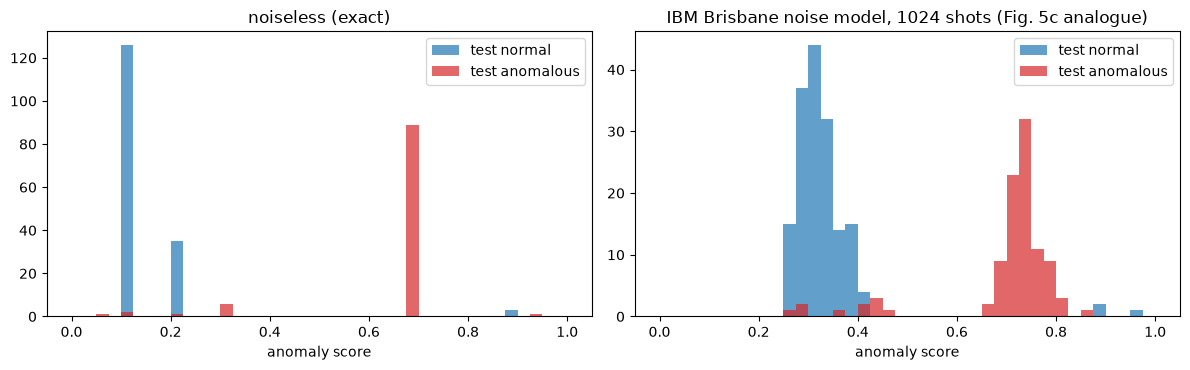

In [20]:
# ---- (b) IBM Brisbane noise profile ----
t0 = time.time()
backend = FakeBrisbane()
noisy_sim = AerSimulator.from_backend(backend)
tqc = transpile(QC, backend, optimization_level=1, seed_transpiler=SEED)
print("transpiled to", backend.name, ": depth", tqc.depth(), "| gates", dict(tqc.count_ops()))
th = model["theta"]                                              # the headline model (first 5,000 normal events, exact engine)
rng_n = np.random.default_rng(SEED)
first_batch = np.arange(64)                                      # "the first batch of testing data"
pos_n = rng_n.choice(np.where(yte_all == 0)[0], NOISE_N, replace=False); pos_a = rng_n.choice(np.where(yte_all == 1)[0], NOISE_N, replace=False)
train_n = np.arange(min(150, N_TRAIN))                           # training events used for the noisy threshold
ev_idx = np.unique(np.r_[first_batch, pos_n, pos_a])
A_ev = angle_scaler(sub0, FIRST_N)(Xte_all.iloc[ev_idx]); A_trn = A_tr[train_n]

def noisy_scores(A):
    circs = [tqc.assign_parameters(dict(zip(QC.parameters, np.hstack([th, a])[COL]))) for a in A]
    job = noisy_sim.run(circs, shots=SHOTS, seed_simulator=SEED)
    r = job.result()
    return np.array([2.0 * r.get_counts(i).get("1", 0) / SHOTS for i in range(len(circs))])

s_noisy_ev = noisy_scores(A_ev); s_noisy_tr = noisy_scores(A_trn)
s_ideal_ev = qae_scores(A_ev, "dense", model["U"], model["ntrash"]); s_ideal_tr = qae_scores(A_trn, "dense", model["U"], model["ntrash"])
y_ev = yte_all[ev_idx]
pos = {int(v): i for i, v in enumerate(ev_idx)}; fb = np.array([pos[int(i)] for i in first_batch])
ratio_first = s_noisy_ev[fb].mean() / s_ideal_ev[fb].mean()
ratio_norm = s_noisy_ev[y_ev == 0].mean() / s_ideal_ev[y_ev == 0].mean(); ratio_anom = s_noisy_ev[y_ev == 1].mean() / s_ideal_ev[y_ev == 1].mean()
ev_ideal = evaluate(s_ideal_tr, s_ideal_ev, y_ev); ev_noisy = evaluate(s_noisy_tr, s_noisy_ev, y_ev)
ev_noisy_fixed = evaluate(s_ideal_tr, s_noisy_ev, y_ev)       # noisy scores against the noiseless threshold
print(f"noisy simulation of {len(ev_idx) + len(train_n)} circuits in {time.time() - t0:.0f} s")
print(f"mean score noisy / noiseless: first 64 test events {ratio_first:.2f}x (paper: about 2.83x) | normal events {ratio_norm:.2f}x | anomalous events {ratio_anom:.2f}x")
display(pd.DataFrame({"noiseless": ev_ideal, "Brisbane noise (own threshold)": ev_noisy, "Brisbane noise, noiseless threshold": ev_noisy_fixed}).T[["f1", "f1_macro", "auroc", "precision", "recall", "fp", "fn", "threshold", "separation"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 41)
for a, sc, ttl in [(ax[0], s_ideal_ev, "noiseless (exact)"), (ax[1], s_noisy_ev, "IBM Brisbane noise model, 1024 shots (Fig. 5c analogue)")]:
    a.hist(sc[y_ev == 0], bins=bins, alpha=0.7, label="test normal", color="tab:blue"); a.hist(sc[y_ev == 1], bins=bins, alpha=0.7, label="test anomalous", color="tab:red")
    a.set_title(ttl); a.set_xlabel("anomaly score"); a.legend()
plt.tight_layout(); plt.show()

## 13. The paper's numbers next to this notebook's

A claim is **reproduced** when the notebook's value is within 0.02 of the paper's (for the noise ratio: within 20 %); **not reached** when
it is lower by more, **exceeded** when higher by more. Qualitative claims are checked by the stated comparison. Because the
paper does not say which F1 it uses, every F1 claim is shown twice: for the anomalous class and macro-averaged.

In [21]:
def mean_std(model, feats, n, exp="table5", col="f1"):
    d = pd.DataFrame([r for r in RESULTS if r["experiment"] == exp and r["model"] == model and r["features"] == feats and r["n_train"] == n])
    return d[col].mean(), d[col].std()

def verdict(paper, ours, tol=0.02):
    if np.isnan(ours): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return f"not reached (gap {ours - paper:+.3f})" if ours < paper else f"exceeded (gap {ours - paper:+.3f})"

rows = []
def add(claim, paper, ours, tol=0.02, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=round(float(ours), 3) if not isinstance(ours, str) else ours,
                     verdict=verdict(paper, ours, tol) if not isinstance(ours, str) else note))

first = res_first
add("Table 1 counts (train/val/test normal+anomalous)", 1.0, float(bool((tab1.values == paper_tab1.values).all())), 0.0)
add("QAE first run, F1 (anomalous class)", 0.87, first["f1"]); add("QAE first run, F1 (macro)", 0.87, first["f1_macro"]); add("QAE first run, AUROC", 0.965, first["auroc"])
for (mdl, nf, n, pf1, pf1s, pauc, paucs, label) in [("QAE dense/RA/1", 8, N_TRAIN, 0.82, 0.040, 0.909, 0.033, "QAE 8F, 5k subsets"),
                                                     ("CAE", 8, N_TRAIN, 0.77, 0.017, 0.901, 0.044, "CAE 8F, 5k subsets"),
                                                     ("CAE", 24, N_TRAIN, 0.77, 0.025, 0.862, 0.066, "CAE 24F, 5k subsets")]:
    f1m, f1s = mean_std(mdl, nf, n, col="f1"); fmm, fms = mean_std(mdl, nf, n, col="f1_macro"); am, as_ = mean_std(mdl, nf, n, col="auroc")
    add(f"{label}: F1 mean (anomalous class)", pf1, f1m); add(f"{label}: F1 mean (macro)", pf1, fmm); add(f"{label}: AUROC mean", pauc, am)
for nf, pf1, pauc in [(8, 0.66, 0.964), (24, 0.87, 0.963)]:
    r = FULL[FULL.features == nf].iloc[0]
    add(f"CAE {nf}F, all 761,875 events: F1 (anomalous class)", pf1, r.f1); add(f"CAE {nf}F, all events: F1 (macro)", pf1, r.f1_macro); add(f"CAE {nf}F, all events: AUROC", pauc, r.auroc)
add("separation, CAE 24F full data", 0.84, SEP_CAE24); add("separation, best QAE", 0.97, SEP_QAE)
d = T4[(T4.encoding == "dense") & (T4.ansatz == "ra") & (T4.reps == 1)].iloc[0]
add("Table 4 Dense/RA/1: F1 (anomalous class)", 0.86, d.f1); add("Table 4 Dense/RA/1: F1 (macro)", 0.86, d.f1_macro); add("Table 4 Dense/RA/1: AUROC", 0.960, d.auroc)
add("Brisbane noise: first-batch score inflation (x)", 2.83, ratio_first, tol=0.2 * 2.83)
add("Brisbane noise: AUROC unchanged (|noisy - noiseless| <= 0.02)", 0.0, abs(ev_noisy["auroc"] - ev_ideal["auroc"]), tol=0.02)
t = T2.set_index("strategy")
add("Table 2: First-N F1 (anomalous class)", 0.798, t.loc["First-N", "f1"]); add("Table 2: First-N F1 (macro)", 0.798, t.loc["First-N", "f1_macro"])
COMP = pd.DataFrame(rows)

# ---- qualitative claims ----
q5 = lambda m, nf, col: mean_std(m, nf, N_TRAIN, col=col)[0]
qual = [
    ("QAE (5k) beats the 8-feature CAE (5k) in AUROC", q5("QAE dense/RA/1", 8, "auroc") > q5("CAE", 8, "auroc")),
    ("QAE (5k) beats the 8-feature CAE (5k) in F1 (anomalous class)", q5("QAE dense/RA/1", 8, "f1") > q5("CAE", 8, "f1")),
    ("QAE (5k) beats the 8-feature CAE (5k) in F1 (macro)", q5("QAE dense/RA/1", 8, "f1_macro") > q5("CAE", 8, "f1_macro")),
    ("QAE trained on 5k beats the 8-feature CAE trained on all data (AUROC)", q5("QAE dense/RA/1", 8, "auroc") > FULL[FULL.features == 8].auroc.iloc[0]),
    ("QAE trained on 5k beats the 8-feature CAE trained on all data (F1 macro)", q5("QAE dense/RA/1", 8, "f1_macro") > FULL[FULL.features == 8].f1_macro.iloc[0]),
    ("QAE beats CAE in AUROC at 1,000 training events", bool(size_tab.loc[("QAE dense/RA/1", min(SIZES)), ("auroc", "mean")] > size_tab.loc[("CAE", min(SIZES)), ("auroc", "mean")])),
    ("Dense/RA/1 is the best of the 12 encoding configurations (mean AUROC)", bool(best_ours.encoding == "dense" and best_ours.ansatz == "ra" and int(best_ours.reps) == 1)),
    ("First-N is the best feature-selection strategy (mean F1, anomalous class)", bool(T2.sort_values("f1", ascending=False).iloc[0].strategy == "First-N")),
    ("First-N is the best feature-selection strategy (mean F1, macro)", bool(T2.sort_values("f1_macro", ascending=False).iloc[0].strategy == "First-N")),
]
QUAL = pd.DataFrame([dict(claim=c, paper="yes", notebook="yes" if ok else "no", verdict="reproduced" if ok else "not reached") for c, ok in qual])
FINAL = pd.concat([COMP, QUAL], ignore_index=True)
FINAL.loc[FINAL.claim.str.startswith("Table 1"), ["paper", "notebook"]] = ["identical", "identical" if bool((tab1.values == paper_tab1.values).all()) else "different"]
display(FINAL)
print(FINAL.verdict.str.split(" ").str[0].value_counts().to_string())
print(f"\ntotal notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min")

,claim,paper,notebook,verdict
0,Table 1 counts (train/val/test normal+anomalous),identical,identical,reproduced
1,"QAE first run, F1 (anomalous class)",0.87,0.937,exceeded (gap +0.067)
2,"QAE first run, F1 (macro)",0.87,0.778,not reached (gap -0.092)
3,"QAE first run, AUROC",0.965,0.914,not reached (gap -0.051)
4,"QAE 8F, 5k subsets: F1 mean (anomalous class)",0.82,0.547,not reached (gap -0.273)
5,"QAE 8F, 5k subsets: F1 mean (macro)",0.82,0.49,not reached (gap -0.330)
6,"QAE 8F, 5k subsets: AUROC mean",0.909,0.878,not reached (gap -0.031)
7,"CAE 8F, 5k subsets: F1 mean (anomalous class)",0.77,0.95,exceeded (gap +0.180)
8,"CAE 8F, 5k subsets: F1 mean (macro)",0.77,0.818,exceeded (gap +0.048)
9,"CAE 8F, 5k subsets: AUROC mean",0.901,0.95,exceeded (gap +0.049)


verdict
not           22
exceeded       9
reproduced     6

total notebook run time: 25.6 min


## 14. Reading the paper critically

The numbers quoted below are from the full run whose outputs are stored in this notebook (seed 42, `FAST_MODE = False`);
re-running gives the same values up to library and thread-count effects.

**What reproduced.** The data (Table 1 counts are identical), the circuit (the 7-qubit SWAP-test circuit matches the exact
simulation to 1e-15, and training with 1024-shot Qiskit sampling lands in the same place as the exact engine), the CAE's
AUROC when it is trained on all normal events (0.969 / 0.958 against the paper's 0.964 / 0.963), the AUROC of a QAE trained
on random 5,000-event subsets within 0.03 of the paper (0.878 +- 0.088 against 0.909 +- 0.033), and the qualitative
Brisbane-noise story (noise inflates the scores of normal events about 2x and leaves anomalous scores alone; the AUROC is
unchanged; the first-batch inflation is 2.3x against 2.83x).

**What did not.** The paper's central claim, that the QAE beats a classical autoencoder in a data-limited setting, does not
hold here. On the same 8 inputs and 5,000 events the CAE reaches AUROC 0.950 +- 0.041 (QAE 0.878 +- 0.088) and, as the
training set grows, the CAE stays at about 0.97 while the QAE climbs from 0.71 (1,000 events) to 0.93 (20,000). A one-class SVM
on the same inputs reaches AUROC 0.967 and macro-F1 0.87, the best F1 values of all models in the table. The QAE's F1 is also far less
stable than the paper's +- 0.04: with the paper's threshold rule, seeds either find a circuit that compresses the normal events
and give F1 around 0.93, or a circuit whose training scores are so spread out that $\mu + 2\sigma$ lands above almost every
test score and the F1 collapses (the mean F1 over 10 random subsets is 0.55 +- 0.43). Dense/RA/1, the paper's best encoding
configuration, is not the best of the twelve here (Dense/RA/3 is), and First-N is the best feature selection by AUROC but not
by F1. The paper's score separation of 0.97 for the QAE is 0.83 here, while the CAE's is 0.98 (paper: 0.84).

**Why the comparison is fragile (points the paper does not discuss).**
1. *The F1 is ambiguous and the test set is 90.7 % anomalous.* Flagging every event gives an anomalous-class F1 of 0.951 and a
   macro-F1 of 0.476, so an anomalous-class F1 of 0.87 would be worse than doing nothing; the paper's numbers read like a
   class-averaged F1. AUROC is the only metric that is comparable across the two readings.
2. *The benchmark is not unsupervised in the way the abstract suggests.* The target encoding of the 18 categorical columns
   uses the 1,269 labelled training anomalies, and three of the feature-selection strategies (ANOVA, mutual information,
   Kendall) use the labels directly.
3. *The train/test split is a strong distribution shift, not a rare-event problem.* In training, normal events never have
   `userId` >= 1000, in the test set 94 % of the anomalous ones do (AUROC 0.97 for that single feature), and test normal events
   differ from training normal events (mount-namespace flag 0.26 versus 0.02). A detector wins by noticing *any* difference
   from the training events, which a one-class SVM does as well as a quantum circuit.
4. *The result depends on which eight features "First-N" selects.* With the order of the Section 3.2 list the QAE reaches
   AUROC 0.88; with the CSV column order (`threadId` second, `returnValue` last) the same code gives AUROC 0.47 and an F1 of 0
   in all five runs (Section 11). Dense-Angle encoding pairs features on a qubit, and `Rz` on a qubit whose `Ry` angle is $\pi$
   changes nothing, so which features share a qubit decides whether `userId` is visible at all. The paper does not give the
   order, the scaling to $[0, \pi]$, the initial parameters, the number of shots, or the CAE architecture.
5. *"60 iterations of batch 64" cannot make the training set size matter.* COBYLA evaluates the cost 60 times on 64 events, i.e.
   at most 3,840 event views for an 8-parameter circuit, whatever the training-set size; the benefit of "more data" for the
   QAE seen above is that more distinct events enter those batches and the threshold statistics, not that the model learns
   more. The CAE has 636 parameters (8 features), the QAE 8, which is what the paper means by parameter efficiency, but a
   one-class SVM with a handful of hyper-parameters does as well.
6. *Nothing here is a quantum advantage test.* The SWAP-test score of this circuit equals the probability that two qubits read 0,
   which a 16 x 16 matrix computes exactly; the circuit is simulated classically, and nothing in the paper establishes an
   advantage on hardware. The only noise study is a simulator.
7. *"Cloud" is only the data source.* The honeypots ran in a cloud, but the features are generic Linux process events; nothing in
   the method is specific to virtualised or cloud environments.

**Verdict for the repository.** The data, circuit, training loop and the noise behaviour reproduce; the headline superiority
over the classical autoencoder, the F1 values and the "Dense/RA/1 best", "First-N best" and separation claims do not, with
the paper's unreported choices (feature order, scaling, CAE design, F1 definition) as the most likely cause.

## 15. Exercises

1. **Feature order.** Section 11 shows that the first eight features in CSV order give AUROC 0.47 and in the Section 3.2 order
   0.88. Try all 8-feature subsets that contain `userId` and one of `returnValue`, `threadId`; which pairing of features on the
   same qubit gives the best Dense-Angle QAE? Explain the result with the Bloch-sphere picture (when is `Rz` invisible?).
2. **The threshold.** Replace $\mu + 2\sigma$ by a quantile of the training scores (say the 99th percentile) or by the best
   threshold on the validation split (the validation file has only 786 anomalous events). How does the spread of the QAE's F1 over 10 subsets change?
3. **A stronger and a weaker benchmark.** Train the CAE with the raw (unscaled) features as in the paper, with fewer gradient
   steps, and with a 2-dimensional latent layer. How much of the QAE-versus-CAE gap in AUROC at 5,000 events is due to the
   benchmark's design?
4. **More expressive circuit.** Use `reps = 3` or `entanglement = "full"` for the RealAmplitudes ansatz and give COBYLA
   the budget it wants (`MAXITER = 300`, or SPSA / ADAM from `qiskit_machine_learning`). Does the QAE's AUROC approach the one-class
   SVM's 0.97? Count parameters and function evaluations on both sides.
5. **Noise.** Replace `FakeBrisbane` by another fake backend (for example `FakeSherbrooke`) or scale the noise model's error
   rates by 0.5 and 2, and recompute the score inflation and the F1 with the noiseless threshold and with a threshold recomputed
   under noise. When does "the metrics remain unchanged" stop being true?